# Лабораторная работа №3 — классификация временных рядов и прогноз погоды

Полный воспроизводимый пайплайн для шести городов России, 2019–2025. Запускать из корня проекта. Исходные Parquet-файлы должны лежать в `data/raw/`.

**Методическое решение:** города объединены в три укрупнённых регионально-климатических режима (по два города в каждом): европейский умеренно-континентальный (Москва, Санкт-Петербург), Черноморский влажный субтропический (Сочи, Геленджик), Дальний Восток (Благовещенск, Находка). Это рабочая группировка для учебной задачи, а не официальная климатическая классификация. На этапе интеграции известное местоположение уточняет городскую модель прогноза.

## 0. Импорт, настройки и карта классов

In [1]:
from pathlib import Path
import re, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, mean_absolute_error, mean_squared_error)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import RidgeClassifier
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox, het_white
from statsmodels.api import add_constant
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.gofplots import qqplot
from IPython.display import display

SEED = 42
# Find the project root even when Jupyter starts in notebooks/ or a parent folder.
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
ROOT = next((p for p in _candidates if (p / 'data' / 'raw').is_dir()), _here)
DATA_DIR = ROOT / 'data' / 'raw'
OUT_DIR = ROOT / 'reports'
OUT_DIR.mkdir(exist_ok=True, parents=True)
FEATURES = ['temperature_2m','relative_humidity_2m','precipitation','rain','snowfall','weathercode','wind_speed_10m','surface_pressure']
SUM_COLS = ['precipitation','rain','snowfall']
CITY_TO_CLIMATE = {
 'Москва':'Умеренно-континентальный', 'Санкт-Петербург':'Умеренно-континентальный',
 'Сочи':'Черноморский субтропический', 'Геленджик':'Черноморский субтропический',
 'Благовещенск':'Дальневосточный муссонный', 'Находка':'Дальневосточный муссонный'}
CITY_NAMES = list(CITY_TO_CLIMATE)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context('notebook')
print('Папка данных:', DATA_DIR, '| parquet:', len(list(DATA_DIR.glob('*.parquet'))))

Папка данных: C:\Users\Kasem Alkhalaf\OneDrive\Desktop\weather_lab_project\weather_lab\data\raw | parquet: 42


## 1. Загрузка и единая дневная частота
Временная колонка определяется автоматически. Для часовых данных применяется дневное среднее для состояния атмосферы и сумма для осадков. Дубликаты времени сворачиваются так же. Для пропусков используются короткая временная интерполяция (до 2 суток) и затем медиана месяца, вычисленная только на доступном ряду; в прогнозной оценке входные признаки ограничены прошлым.

In [2]:
def read_city_file(path):
    city = path.name.split('_')[0]
    raw = pd.read_parquet(path).reset_index()
    # Open-Meteo exports may store time in a column or in the index.
    candidates = [c for c in raw.columns if str(c).lower() in {'time','date','datetime','timestamp'}]
    if not candidates:
        candidates = [c for c in raw.columns if 'time' in str(c).lower() or 'date' in str(c).lower()]
    if not candidates:
        candidates = [raw.columns[0]]
    tcol = candidates[0]
    raw[tcol] = pd.to_datetime(raw[tcol], errors='coerce', utc=True).dt.tz_convert(None)
    raw = raw.dropna(subset=[tcol]).set_index(tcol).sort_index()
    raw = raw.loc[:, ~raw.columns.duplicated()]
    present = [c for c in FEATURES if c in raw.columns]
    raw = raw[present].apply(pd.to_numeric, errors='coerce')
    agg = {c:('sum' if c in SUM_COLS else ('mode' if c=='weathercode' else 'mean')) for c in present}
    # Convert the categorical weather code to the day's most frequent observed code.
    if 'weathercode' in agg:
        agg['weathercode'] = lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
    daily = raw.resample('D').agg(agg)
    daily['city'] = city
    return daily

files = sorted(DATA_DIR.glob('*.parquet'))
assert files, 'Не найдены Parquet в data/raw. Распакуйте архив с данными.'
frames = [read_city_file(f) for f in files]
data = pd.concat(frames).reset_index(names='date').sort_values(['city','date'])
data = data[data.city.isin(CITY_TO_CLIMATE)].copy()
# Collapse any year-file boundary duplicates.
agg = {c:('sum' if c in SUM_COLS else 'mean') for c in FEATURES if c in data.columns}
data = data.groupby(['city','date'])[list(agg)].agg(agg).reset_index()
data['climate'] = data.city.map(CITY_TO_CLIMATE)
print(data.shape, data.date.min(), data.date.max())
display(data.groupby('city').agg(days=('date','size'), start=('date','min'), end=('date','max')))
display(data.groupby('city')[FEATURES].apply(lambda x: x.isna().mean()).round(3))

(15342, 11) 2019-01-01 00:00:00 2025-12-31 00:00:00


,days,start,end
city,,,
Благовещенск,2557,2019-01-01,2025-12-31
Геленджик,2557,2019-01-01,2025-12-31
Москва,2557,2019-01-01,2025-12-31
Находка,2557,2019-01-01,2025-12-31
Санкт-Петербург,2557,2019-01-01,2025-12-31
Сочи,2557,2019-01-01,2025-12-31


,temperature_2m,relative_humidity_2m,precipitation,rain,snowfall,weathercode,wind_speed_10m,surface_pressure
city,,,,,,,,
Благовещенск,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Геленджик,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Москва,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Находка,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Санкт-Петербург,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Сочи,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 1.1 Пропуски и подготовка рядов

In [3]:
# Restore a complete daily index per city, then interpolate only short gaps.
series = {}
missing_summary = []
for city, g in data.groupby('city'):
    g = g.set_index('date').sort_index().reindex(pd.date_range(g.date.min(), g.date.max(), freq='D', name='date'))
    before = g[FEATURES].isna().mean()
    x = g[FEATURES].copy()
    # Interpolate only continuous state variables across short gaps; do not interpolate rainfall totals or categorical weather codes.
    continuous = [c for c in x.columns if c not in SUM_COLS + ['weathercode']]
    x[continuous] = x[continuous].interpolate(method='time', limit=2, limit_direction='both')
    # Precipitation/snow and weather codes use monthly modes; other features use monthly medians.
    for col in x.columns:
        if col == 'weathercode':
            month_mode = x[col].groupby(x.index.month).transform(lambda v: v.mode().iloc[0] if not v.mode().empty else np.nan)
            x[col] = x[col].fillna(month_mode).fillna(x[col].mode().iloc[0] if not x[col].mode().empty else 0)
        else:
            x[col] = x[col].fillna(x[col].groupby(x.index.month).transform('median')).fillna(x[col].median())
    g[FEATURES] = x
    g['city'] = city
    g['climate'] = CITY_TO_CLIMATE[city]
    series[city] = g
    missing_summary.append(pd.DataFrame({'city':city,'feature':before.index,'missing_rate_before':before.values,
                                        'missing_rate_after':g[FEATURES].isna().mean().values}))
missing_summary = pd.concat(missing_summary, ignore_index=True)
display(missing_summary.pivot(index='feature',columns='city',values='missing_rate_before').round(3))
print('Пропусков после заполнения:', sum(x[FEATURES].isna().sum().sum() for x in series.values()))
climate_norms={city: d.loc[d.index.year<=2023,'temperature_2m'].groupby(d.loc[d.index.year<=2023].index.dayofyear).mean().to_dict() for city,d in series.items()}


city,Благовещенск,Геленджик,Москва,Находка,Санкт-Петербург,Сочи
feature,,,,,,
precipitation,0.0,0.0,0.0,0.0,0.0,0.0
rain,0.0,0.0,0.0,0.0,0.0,0.0
relative_humidity_2m,0.0,0.0,0.0,0.0,0.0,0.0
snowfall,0.0,0.0,0.0,0.0,0.0,0.0
surface_pressure,0.0,0.0,0.0,0.0,0.0,0.0
temperature_2m,0.0,0.0,0.0,0.0,0.0,0.0
weathercode,0.0,0.0,0.0,0.0,0.0,0.0
wind_speed_10m,0.0,0.0,0.0,0.0,0.0,0.0


Пропусков после заполнения: 0


## 2. EDA по каждому городу: тренд, сезонность, распределения, корреляции

### Благовещенск


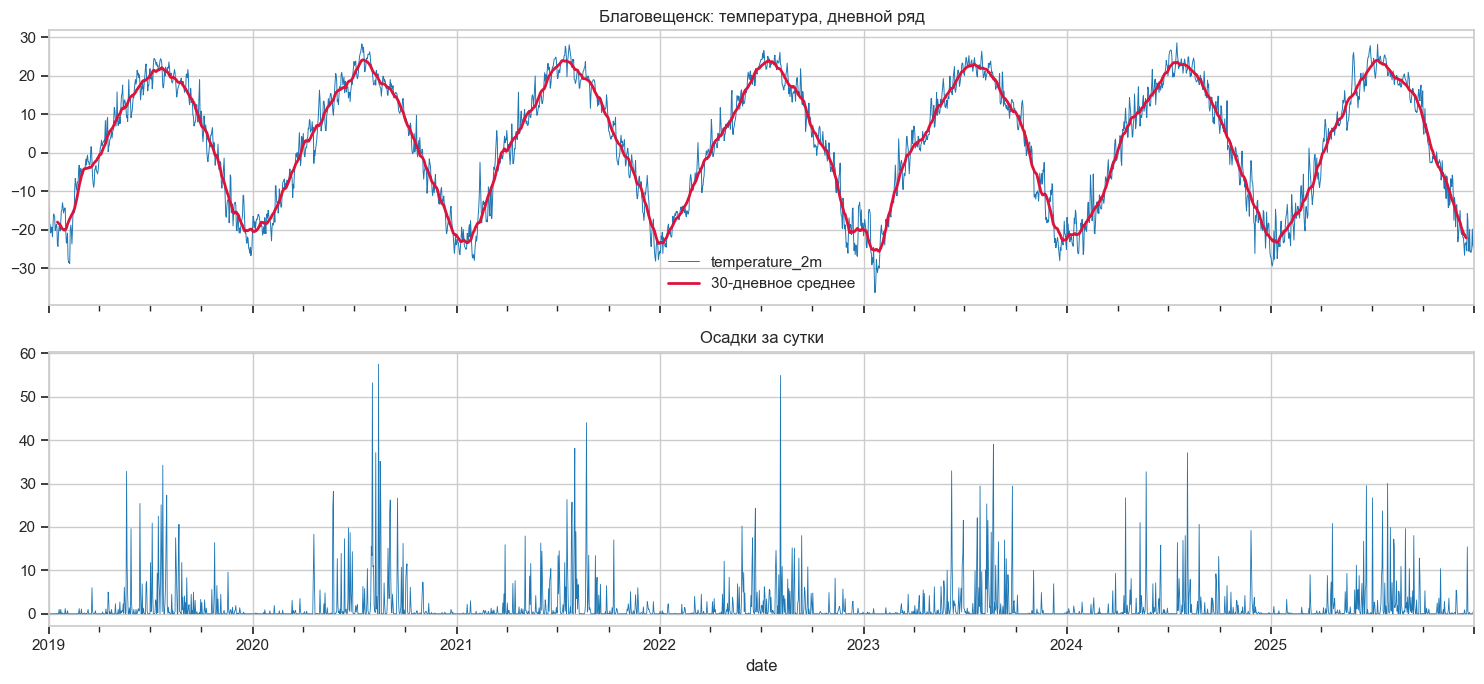

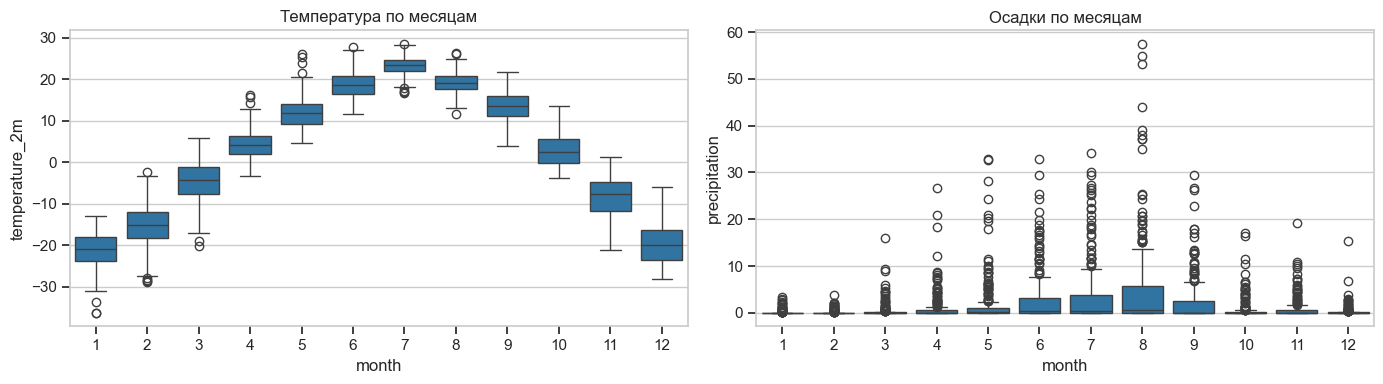

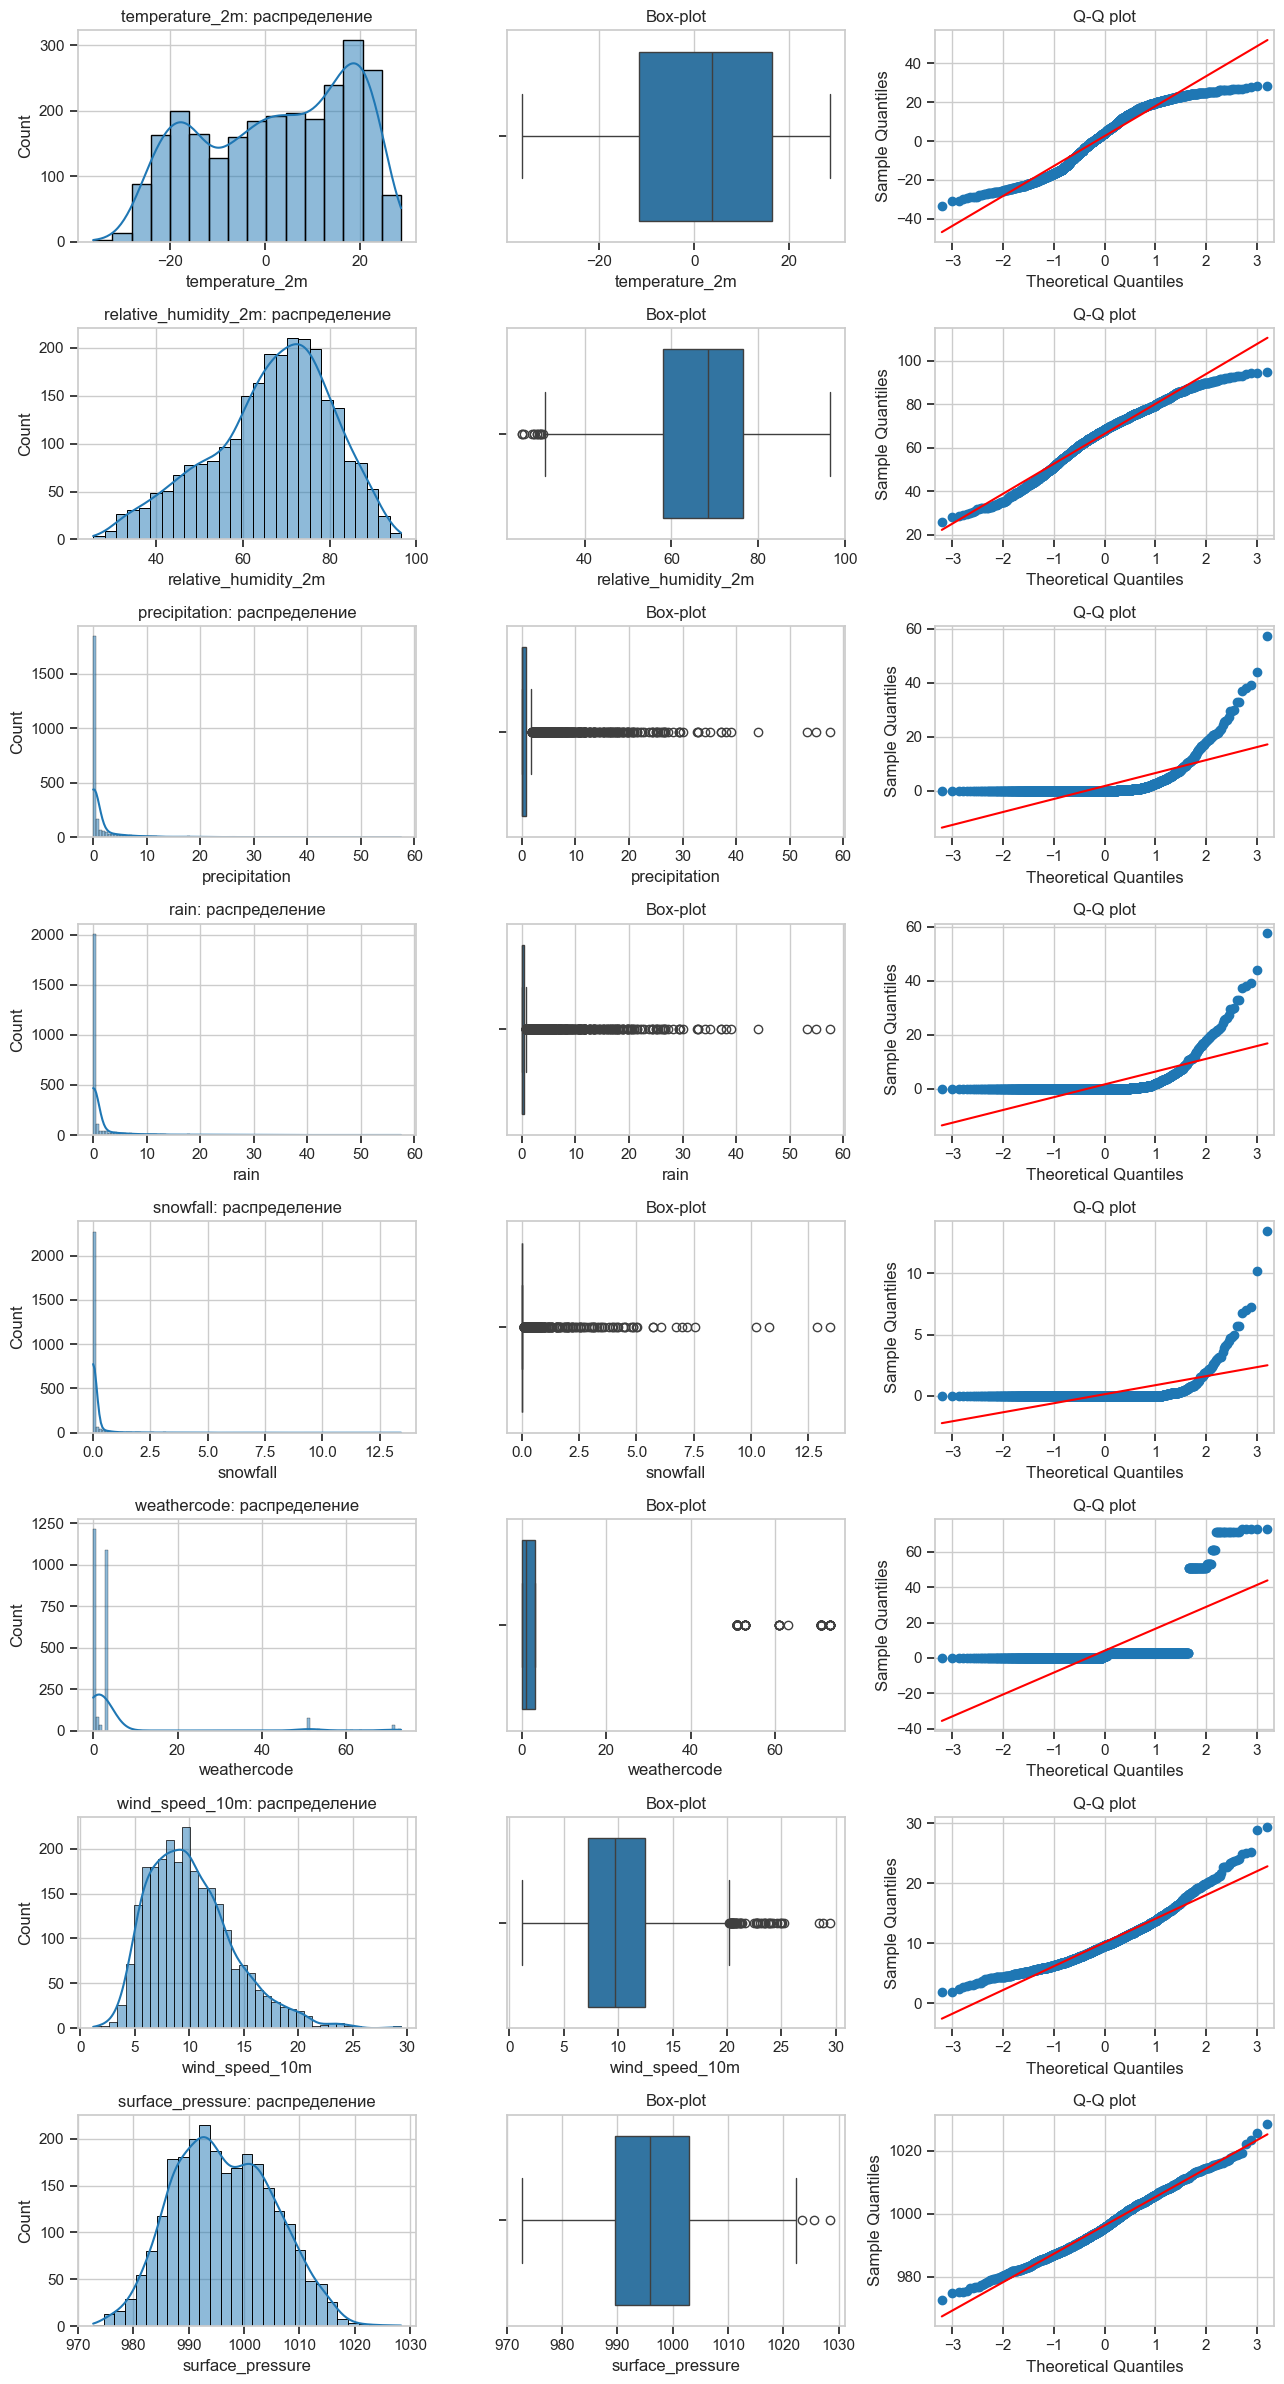

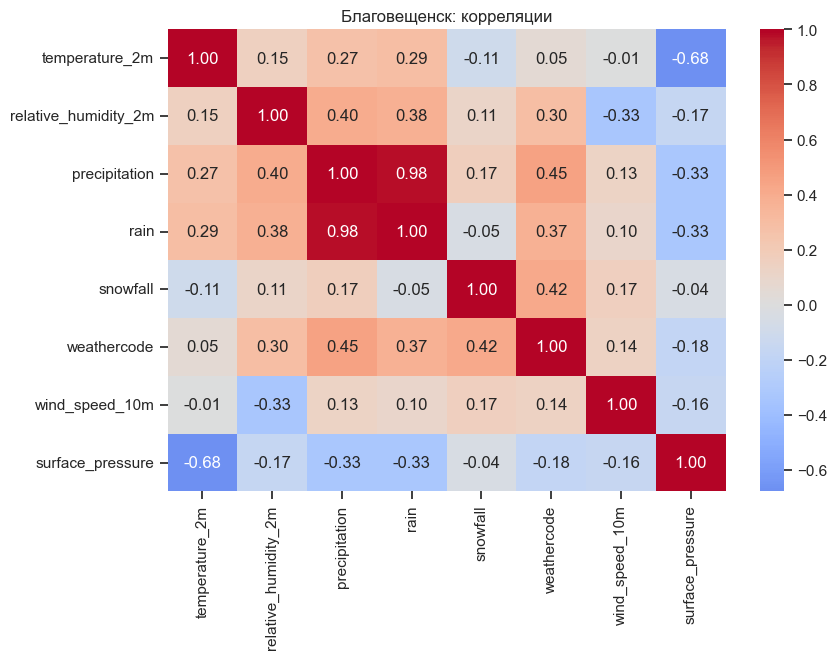

,count,mean,std,min,25%,50%,75%,max
temperature_2m,2557.0,2.21,15.60,-36.29,-11.63,3.82,16.47,28.57
relative_humidity_2m,2557.0,66.51,13.95,25.58,58.04,68.33,76.50,96.46
precipitation,2557.0,1.74,4.93,0.00,0.00,0.00,0.70,57.50
rain,2557.0,1.53,4.86,0.00,0.00,0.00,0.30,57.50
snowfall,2557.0,0.15,0.75,0.00,0.00,0.00,0.00,13.44
weathercode,2557.0,4.53,13.27,0.00,0.00,1.00,3.00,73.00
wind_speed_10m,2557.0,10.19,3.95,1.17,7.25,9.68,12.43,29.45
surface_pressure,2557.0,996.42,8.89,972.73,989.62,995.85,1002.96,1028.41


### Геленджик


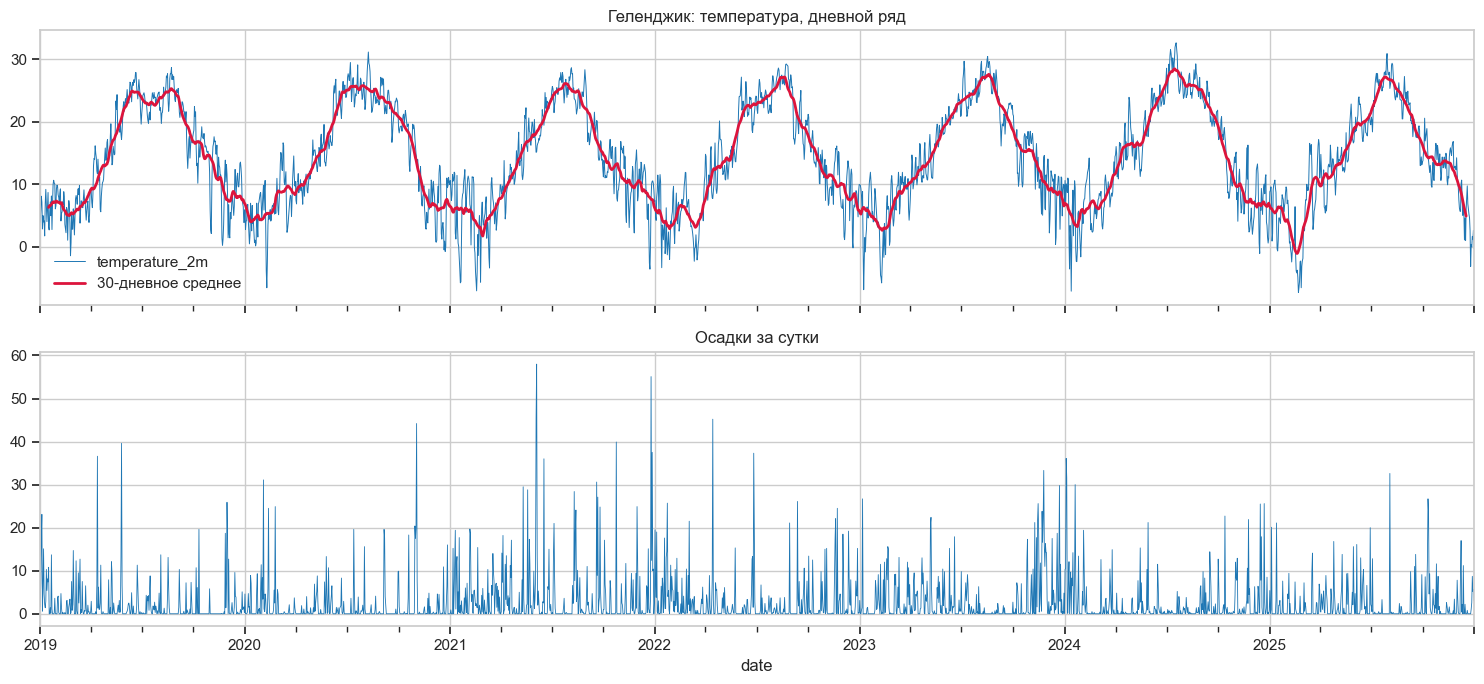

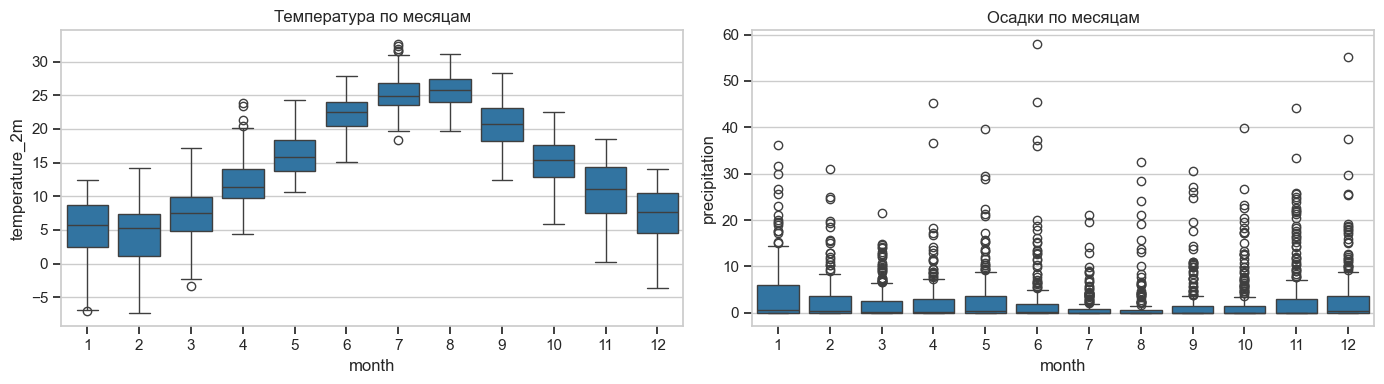

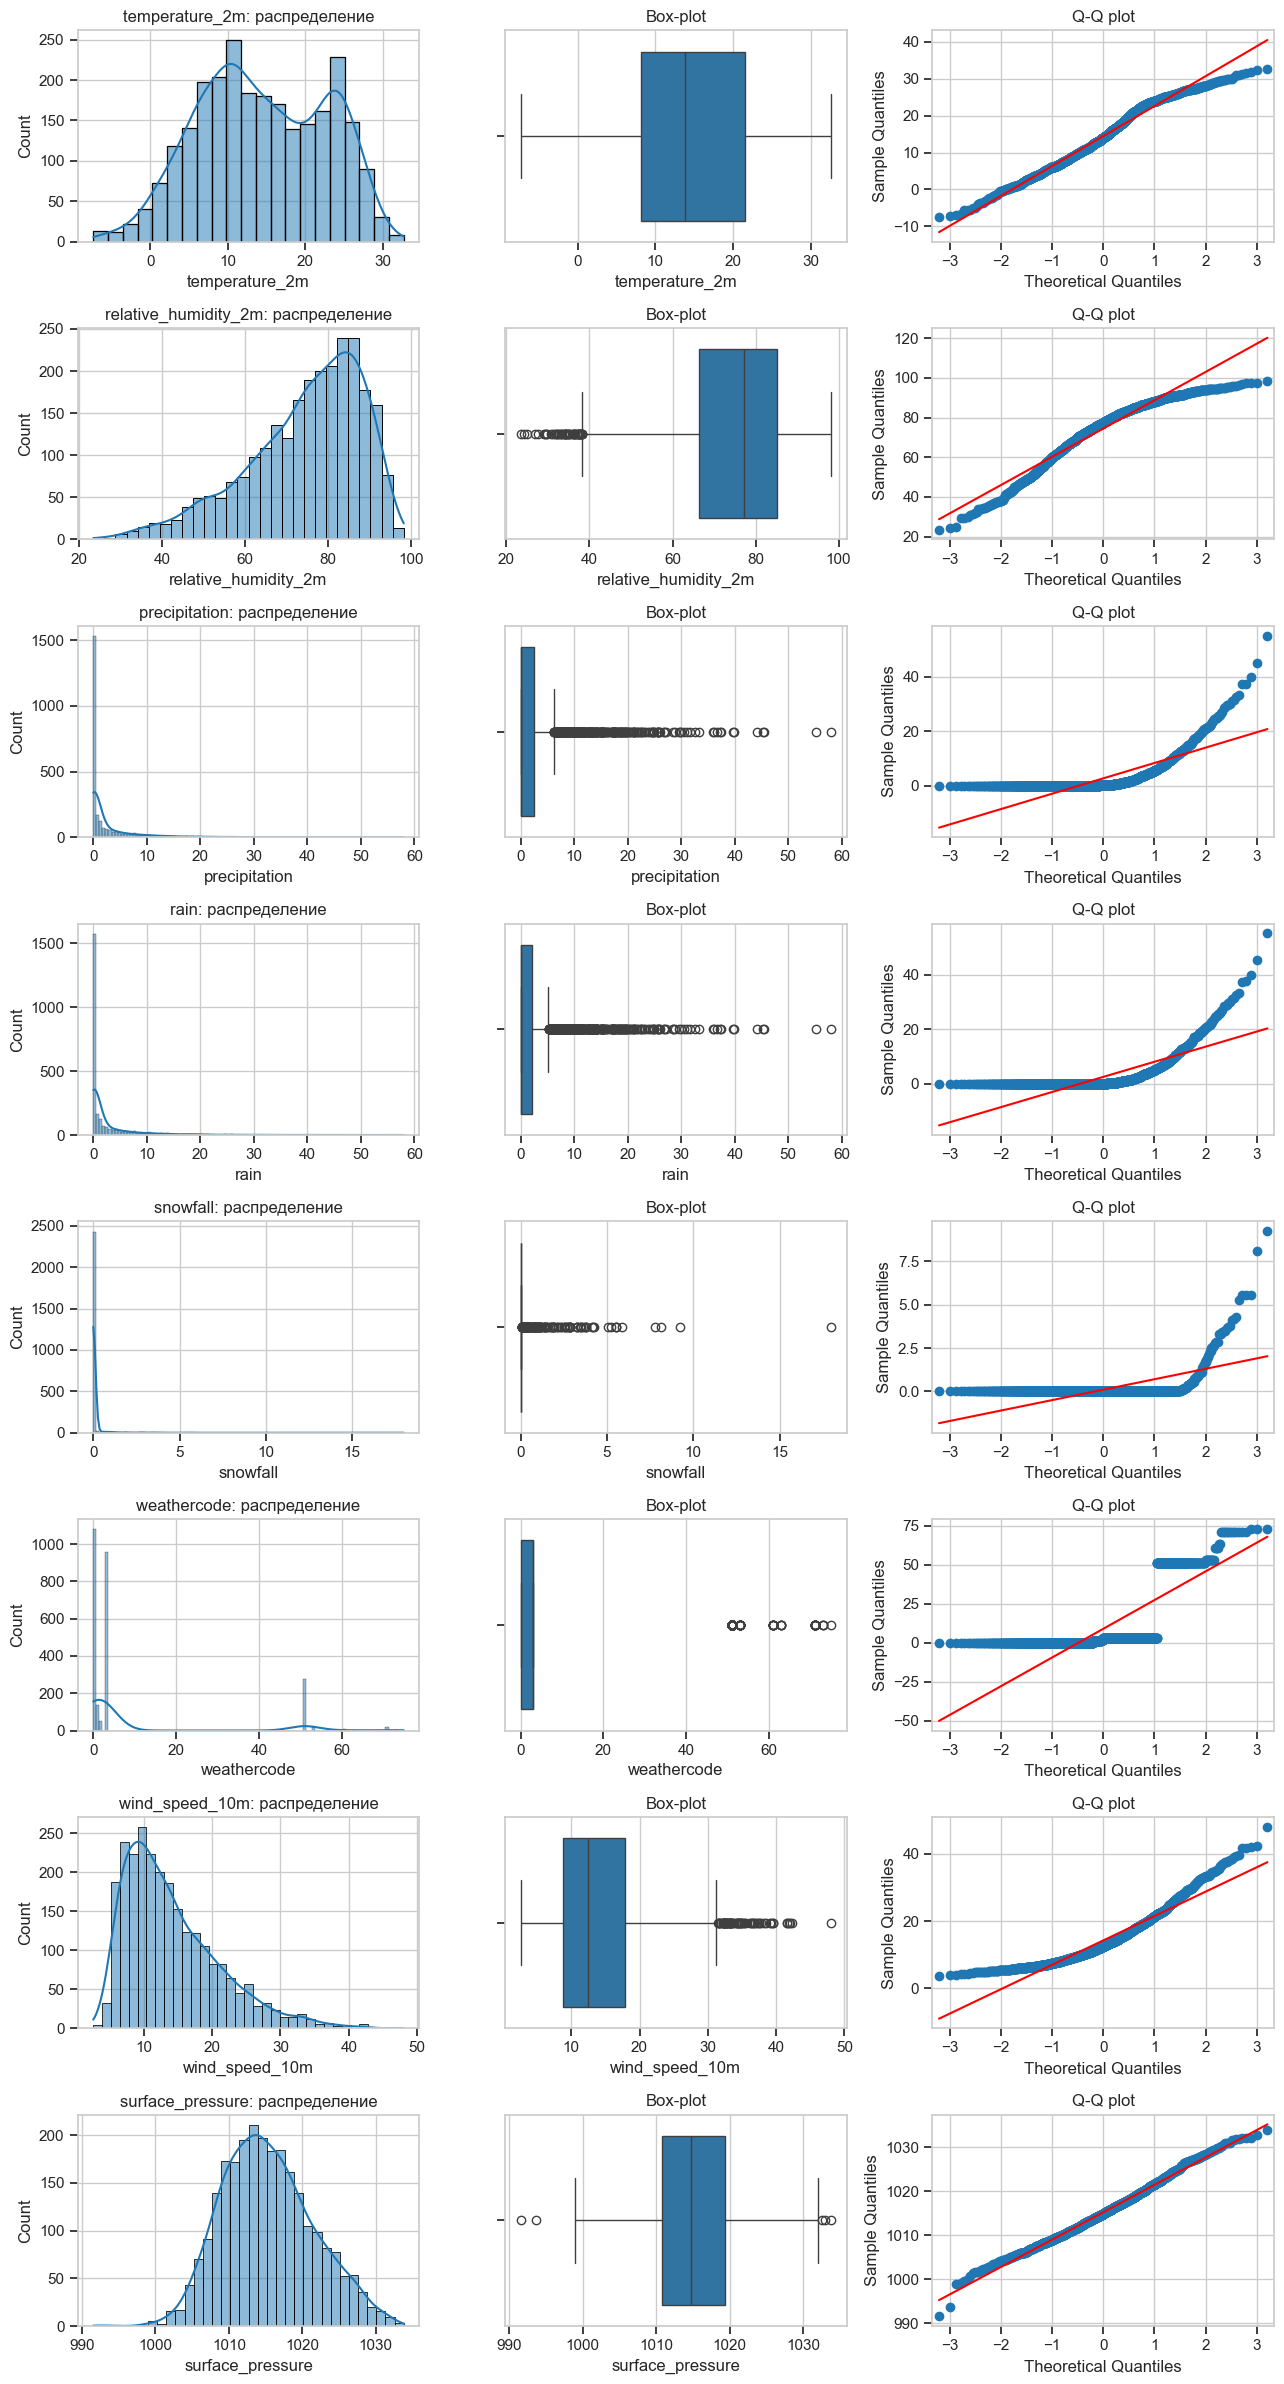

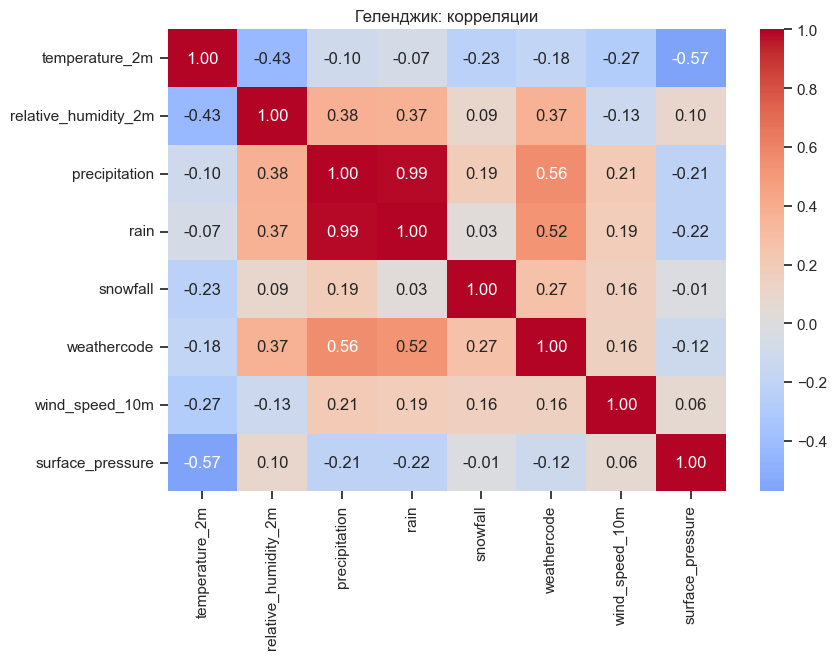

,count,mean,std,min,25%,50%,75%,max
temperature_2m,2557.0,14.36,8.16,-7.33,8.21,13.88,21.59,32.65
relative_humidity_2m,2557.0,74.44,13.96,23.42,66.42,77.25,85.21,98.21
precipitation,2557.0,2.59,5.57,0.00,0.00,0.10,2.50,58.00
rain,2557.0,2.46,5.46,0.00,0.00,0.10,2.10,58.00
snowfall,2557.0,0.09,0.64,0.00,0.00,0.00,0.00,17.99
weathercode,2557.0,8.16,17.60,0.00,0.00,3.00,3.00,75.00
wind_speed_10m,2557.0,14.02,6.91,2.59,8.79,12.46,17.87,48.05
surface_pressure,2557.0,1015.33,6.21,991.53,1010.84,1014.79,1019.38,1033.82


### Москва


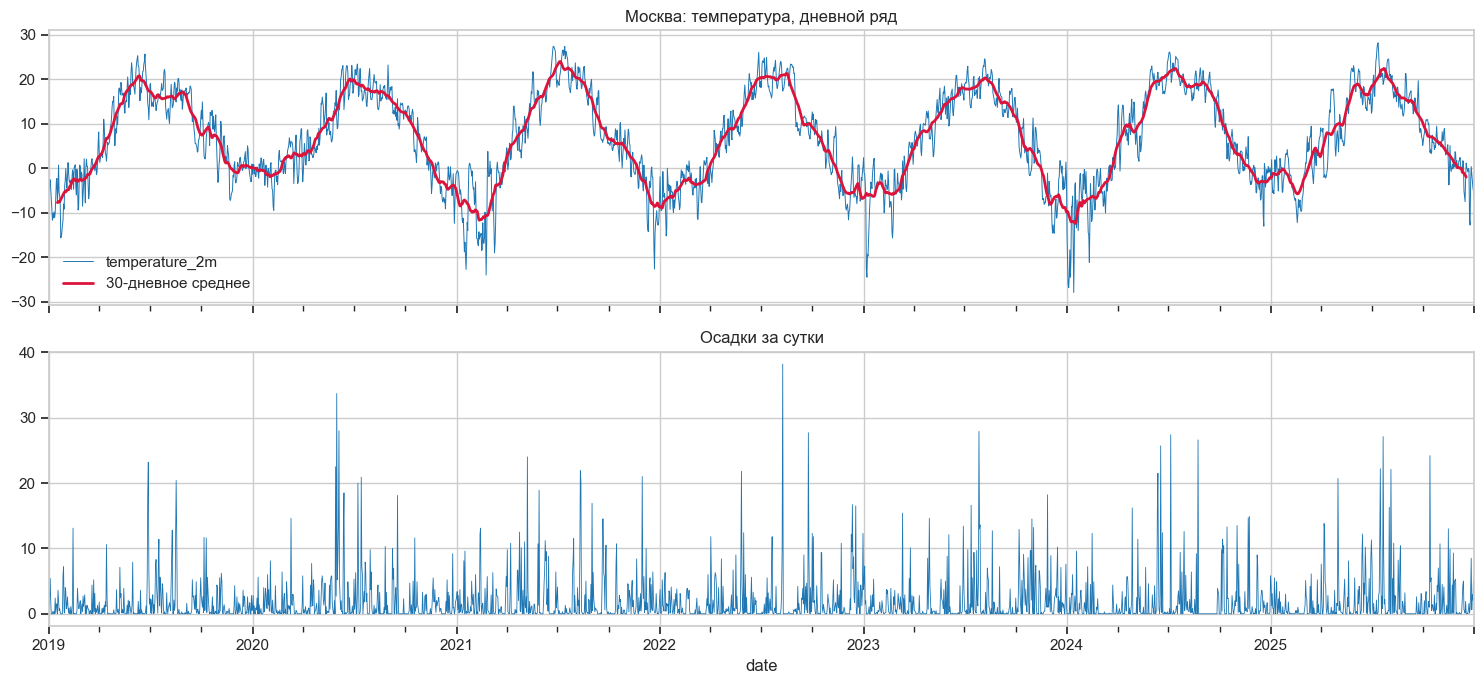

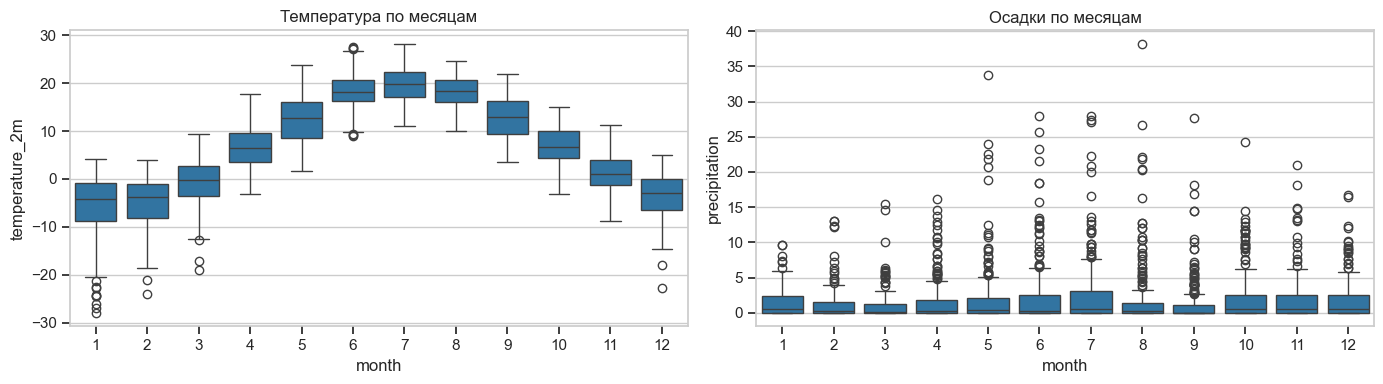

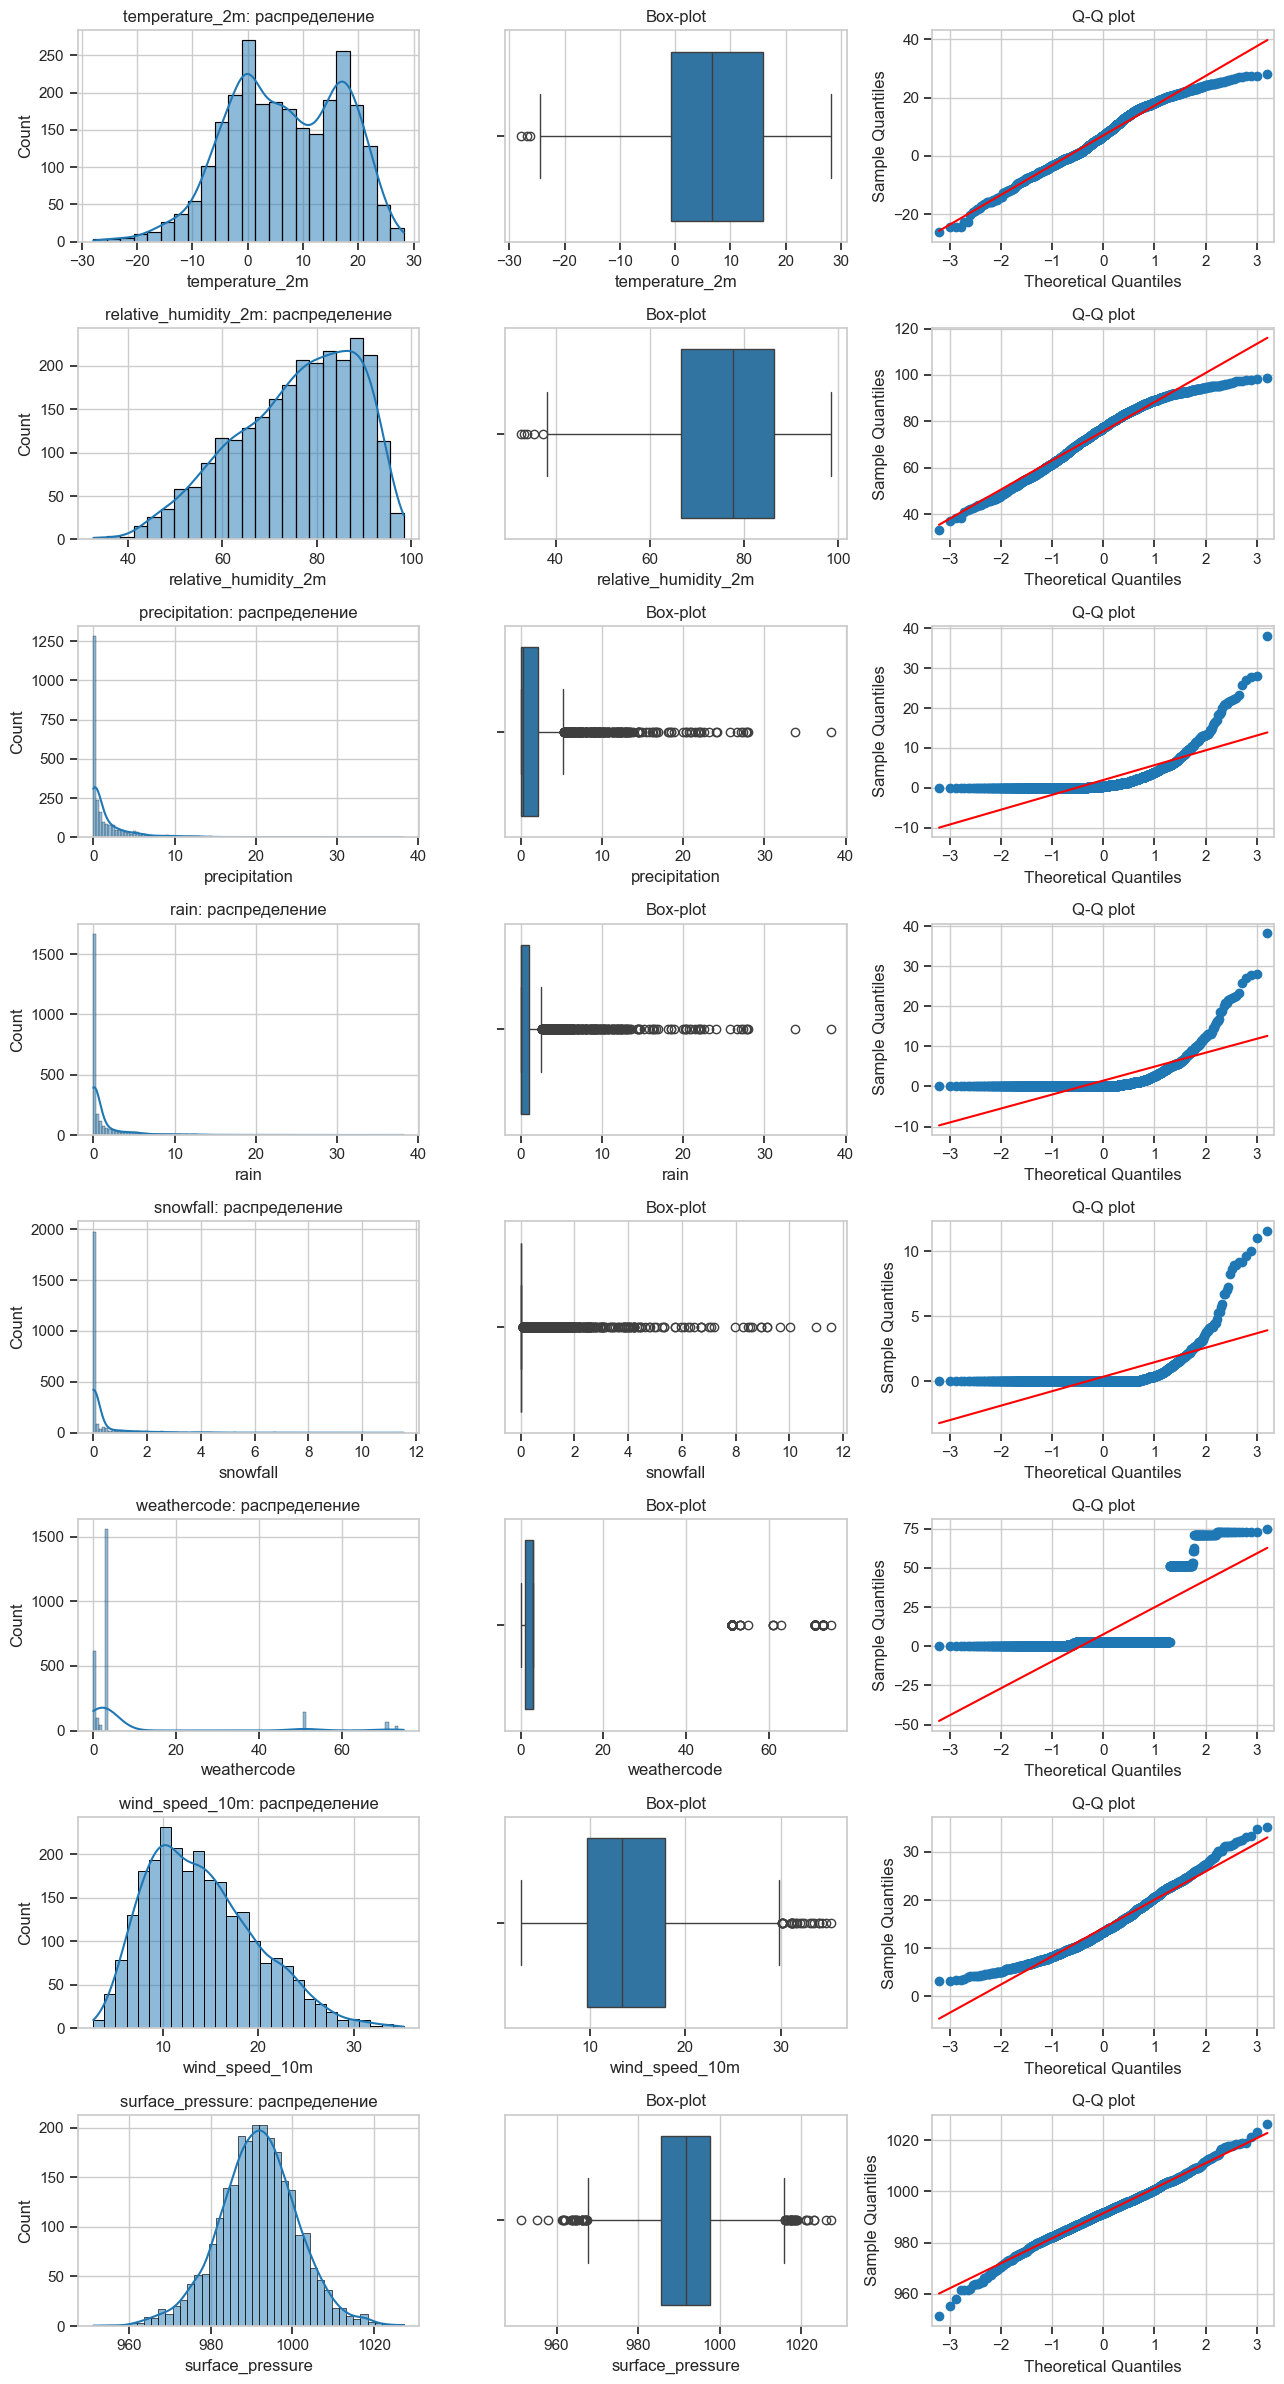

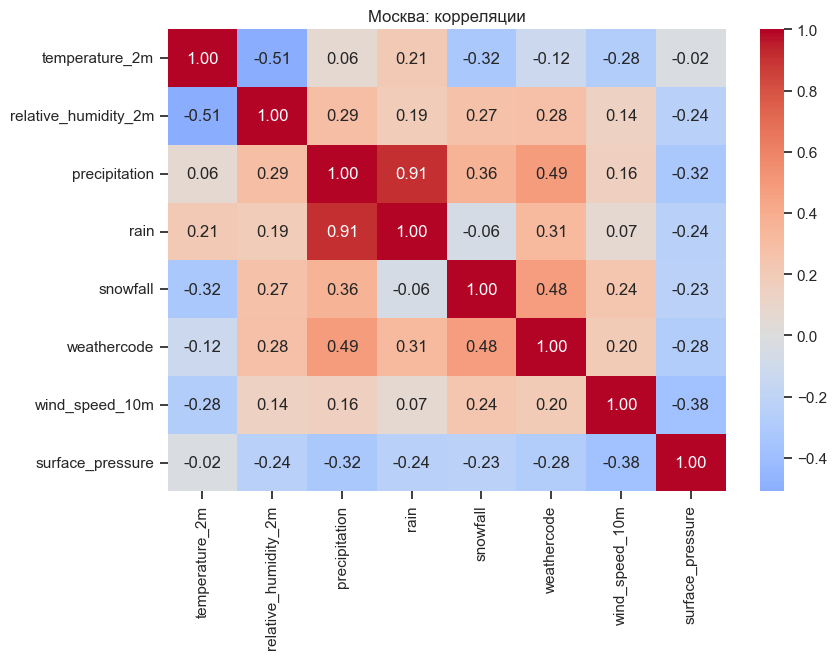

,count,mean,std,min,25%,50%,75%,max
temperature_2m,2557.0,6.83,10.24,-27.94,-0.83,6.60,15.93,28.22
relative_humidity_2m,2557.0,75.76,12.92,32.54,66.71,77.75,86.33,98.54
precipitation,2557.0,1.86,3.64,0.00,0.00,0.30,2.10,38.20
rain,2557.0,1.37,3.40,0.00,0.00,0.00,1.00,38.20
snowfall,2557.0,0.34,1.07,0.00,0.00,0.00,0.00,11.55
weathercode,2557.0,7.63,17.25,0.00,1.00,3.00,3.00,75.00
wind_speed_10m,2557.0,14.14,5.76,2.73,9.72,13.39,17.82,35.26
surface_pressure,2557.0,991.62,9.69,951.18,985.61,991.71,997.75,1027.34


### Находка


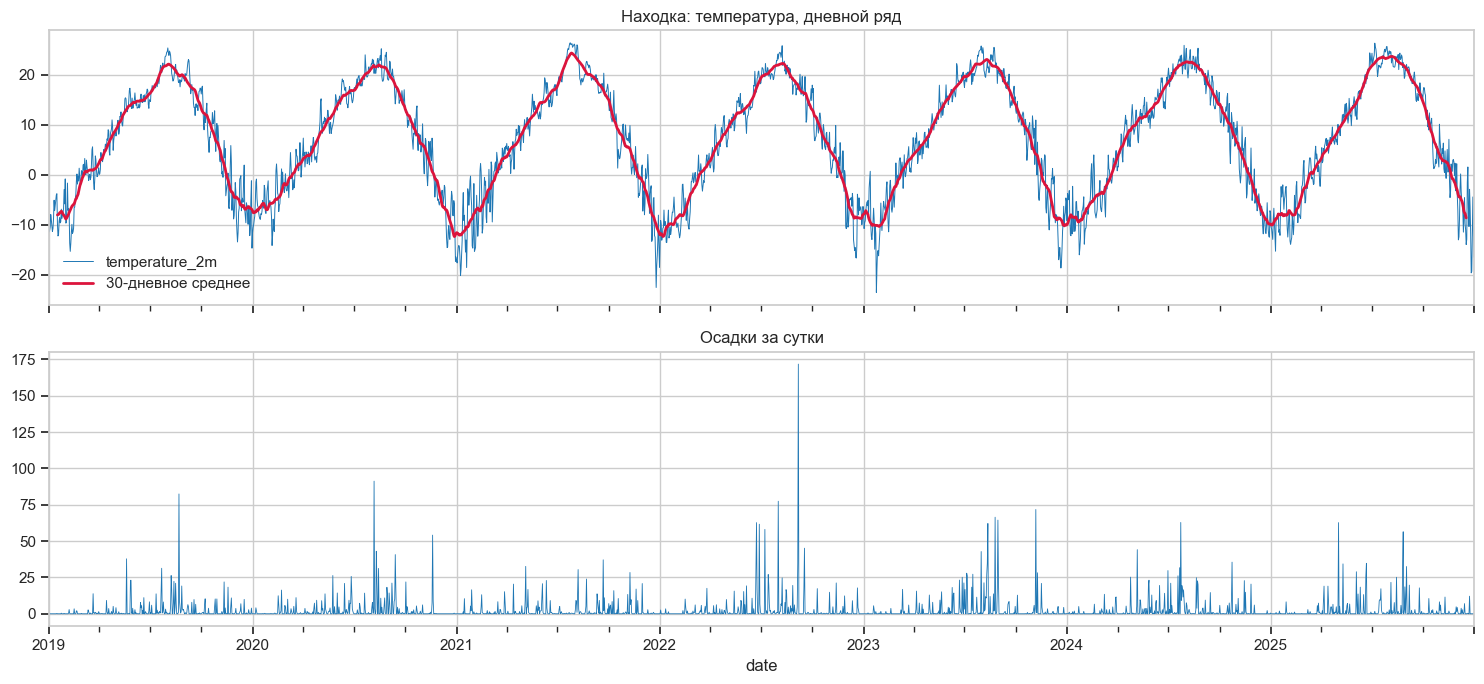

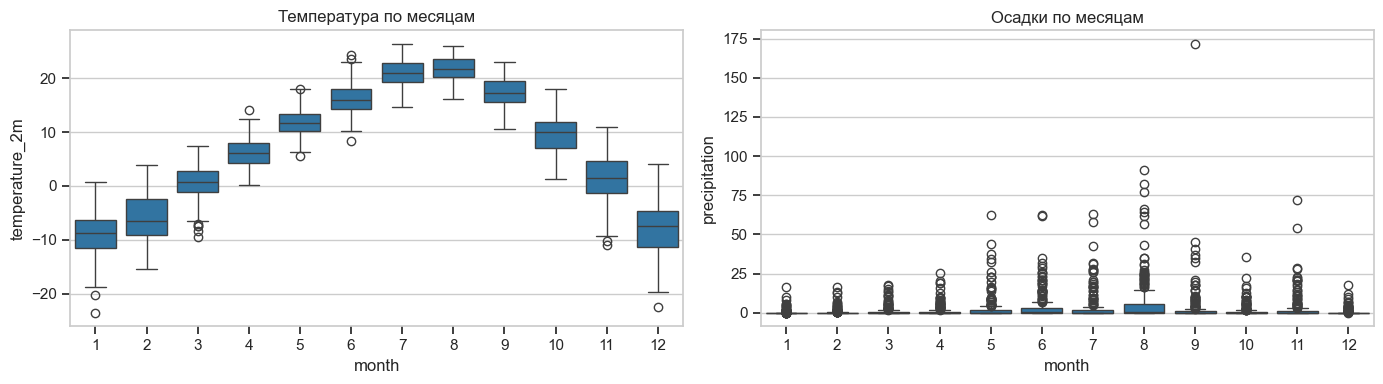

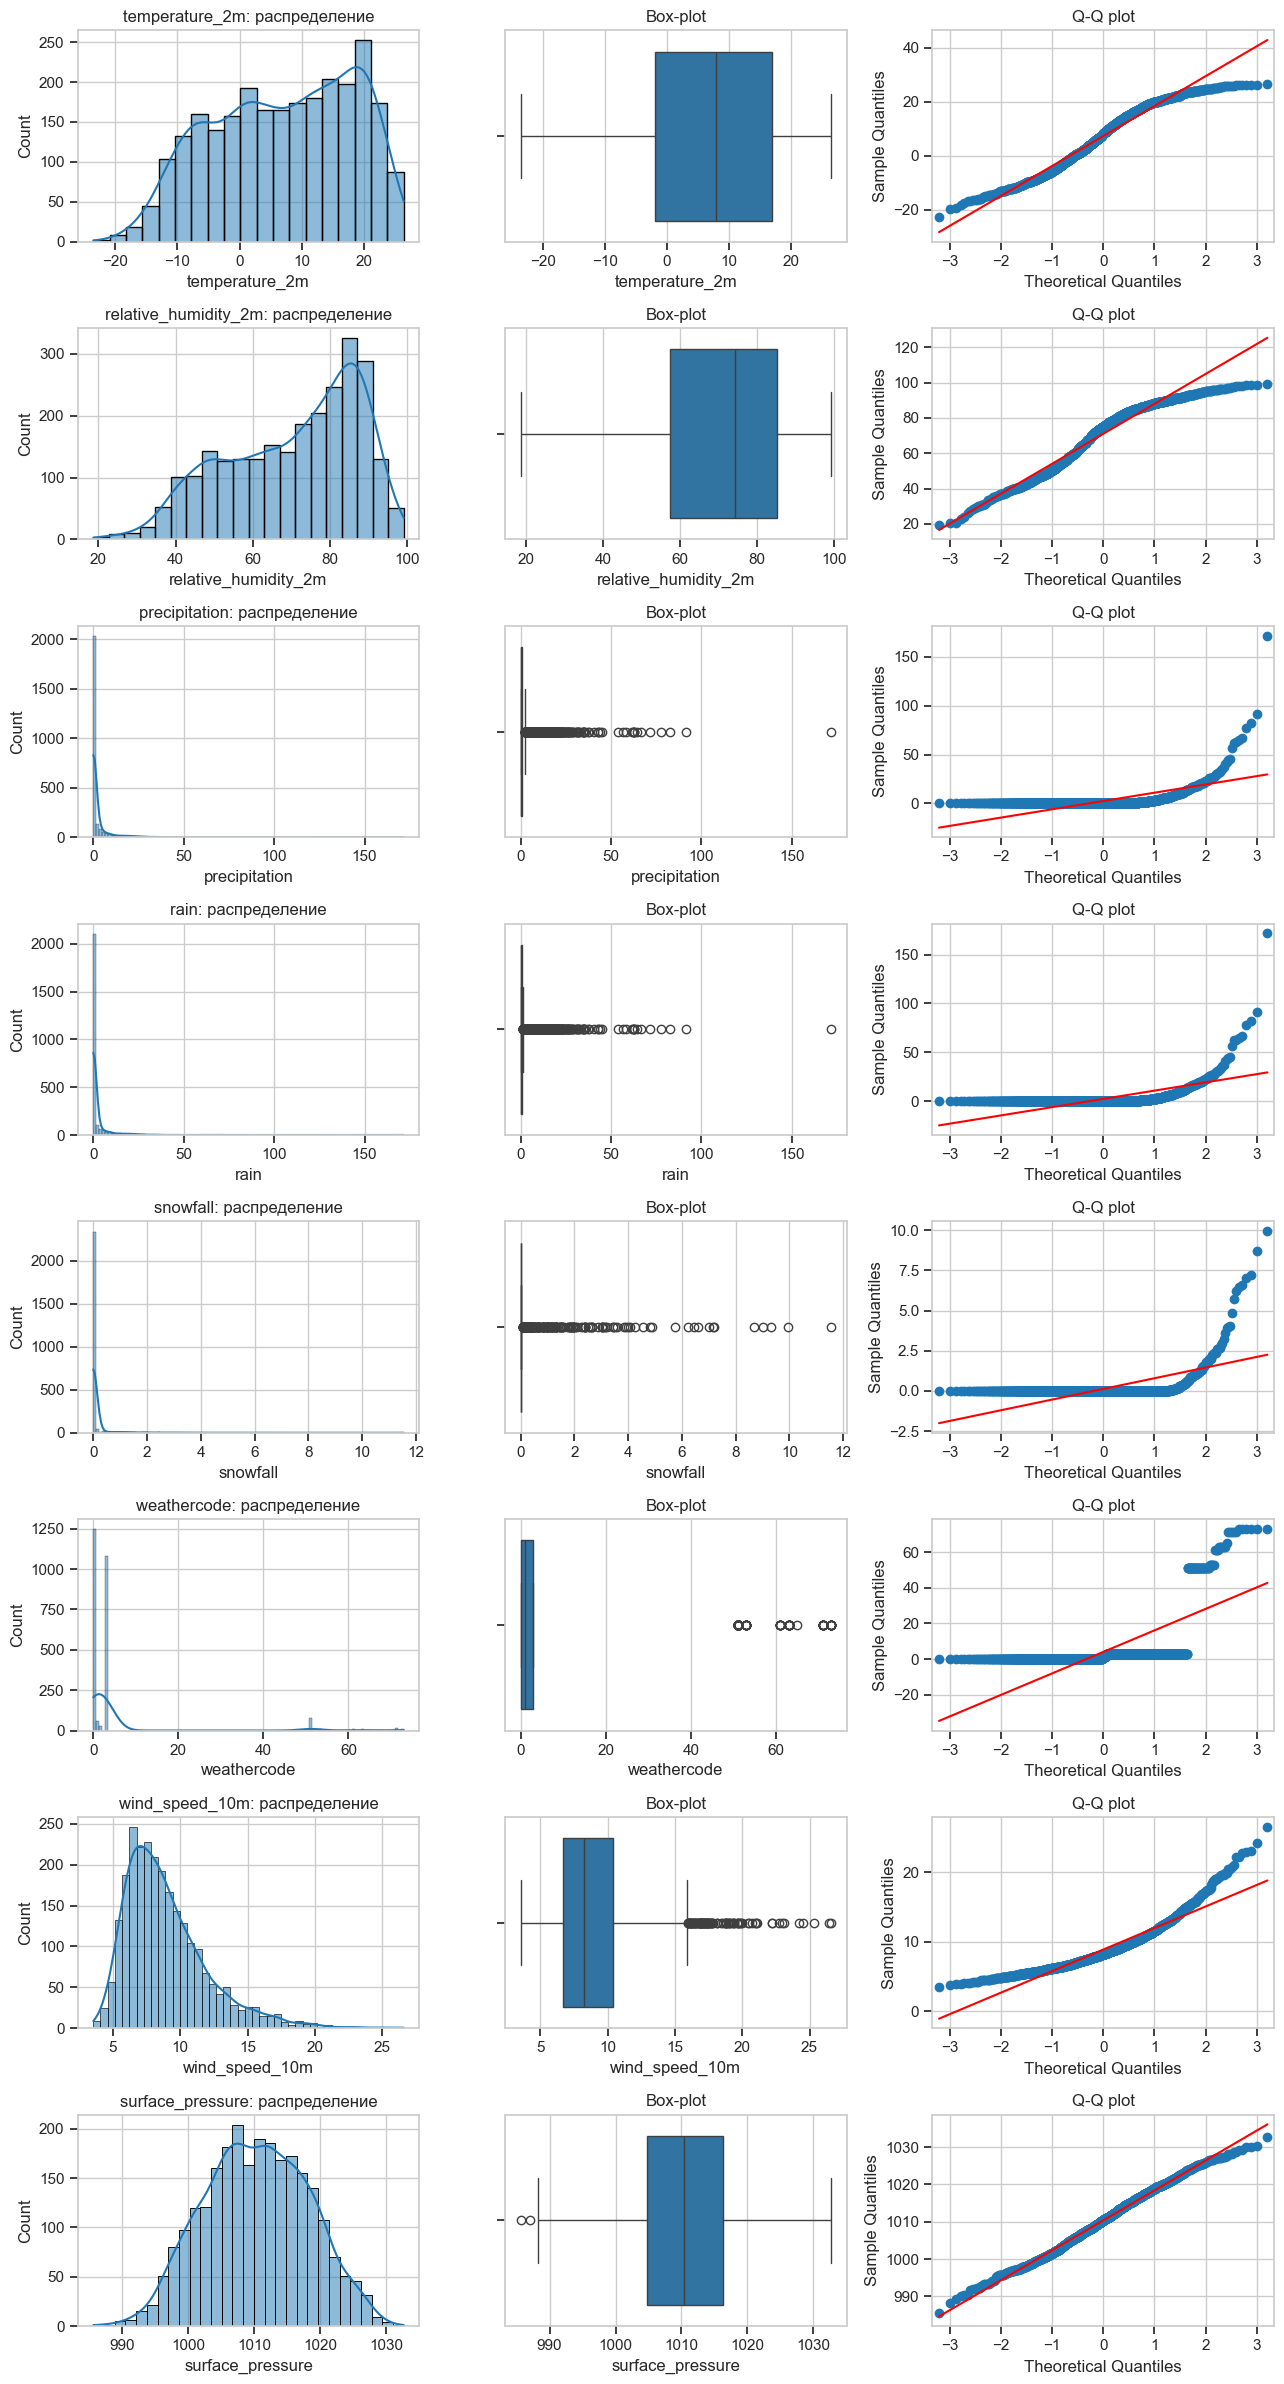

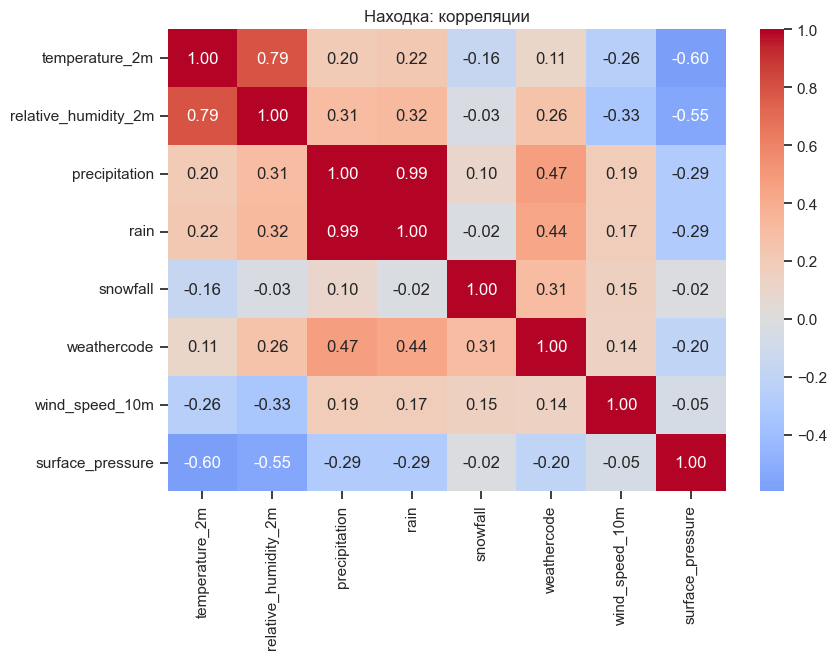

,count,mean,std,min,25%,50%,75%,max
temperature_2m,2557.0,6.99,11.17,-23.55,-1.90,7.83,16.85,26.40
relative_humidity_2m,2557.0,70.57,17.13,18.67,57.46,74.33,85.04,99.21
precipitation,2557.0,2.43,7.96,0.00,0.00,0.00,0.90,171.70
rain,2557.0,2.25,7.92,0.00,0.00,0.00,0.50,171.70
snowfall,2557.0,0.13,0.70,0.00,0.00,0.00,0.00,11.55
weathercode,2557.0,4.32,12.60,0.00,0.00,1.00,3.00,73.00
wind_speed_10m,2557.0,8.96,3.10,3.55,6.72,8.28,10.40,26.60
surface_pressure,2557.0,1010.37,7.85,985.62,1004.78,1010.43,1016.23,1032.67


### Санкт-Петербург


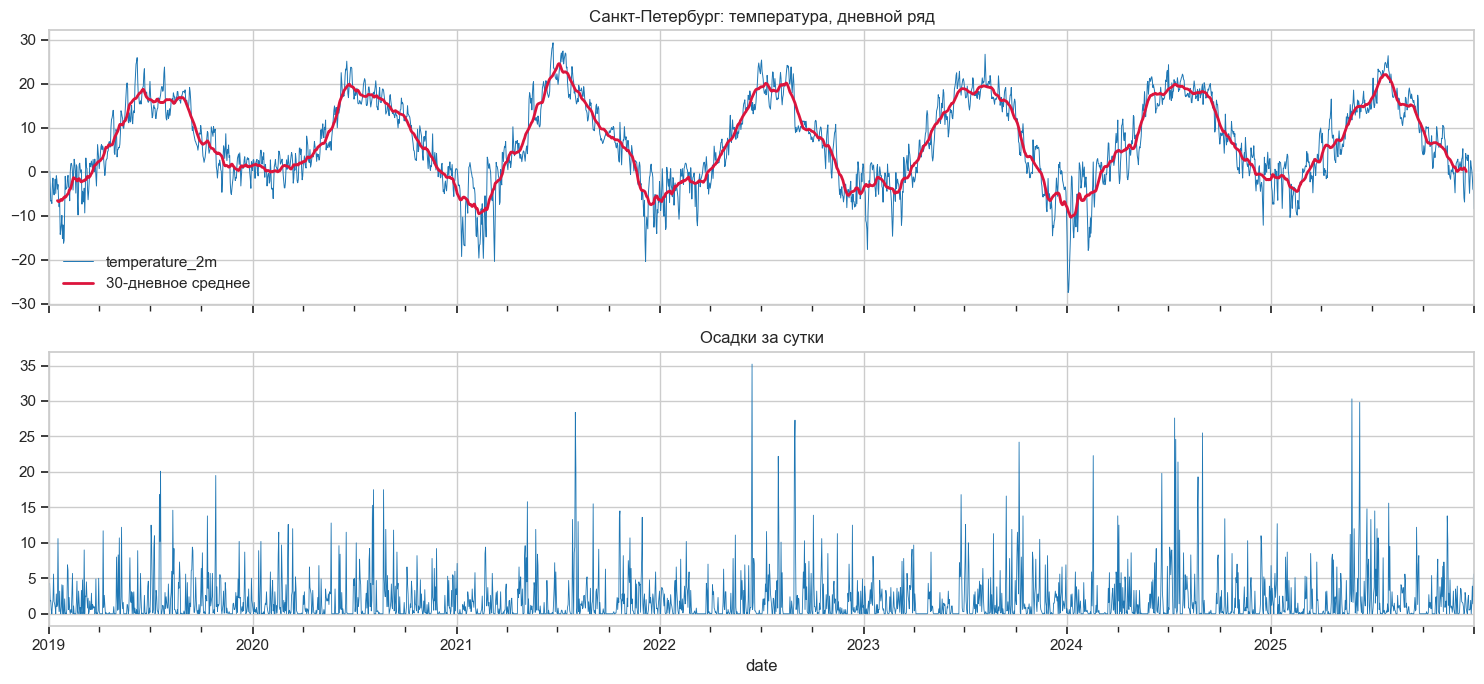

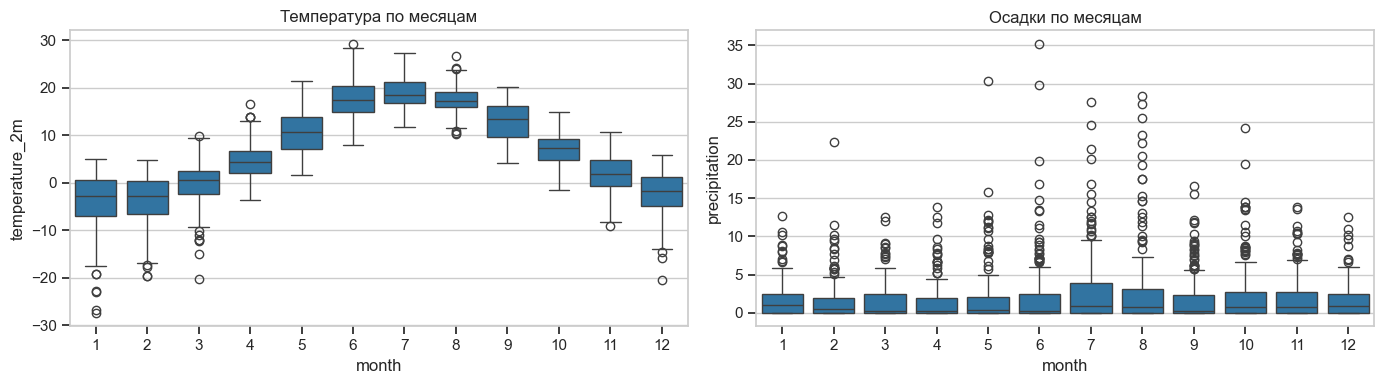

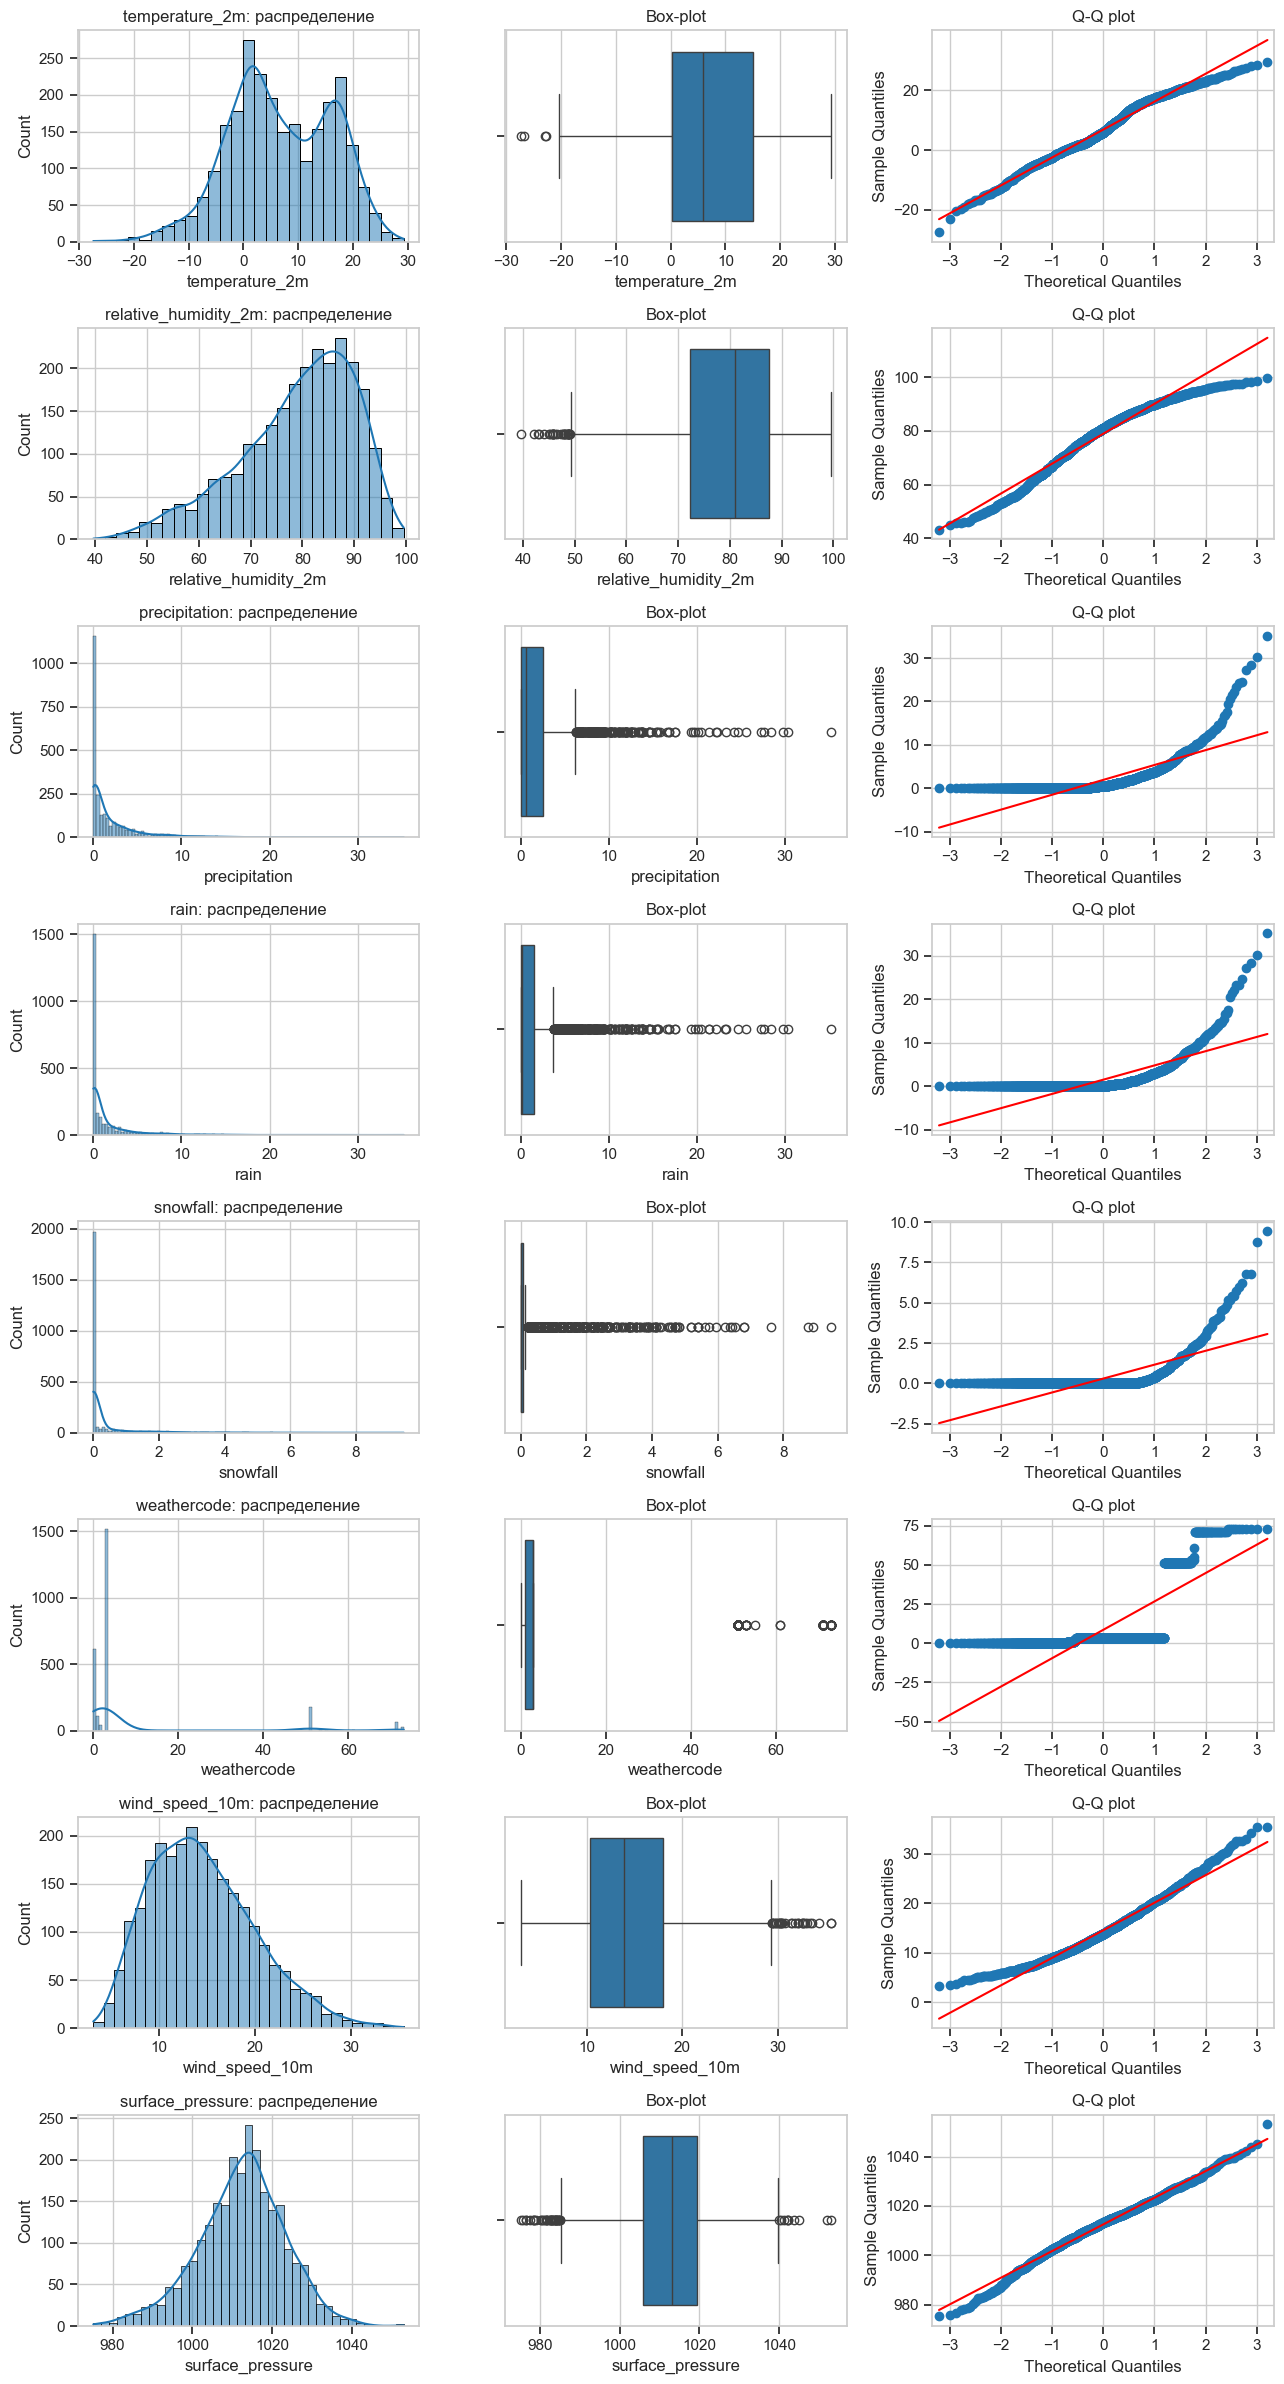

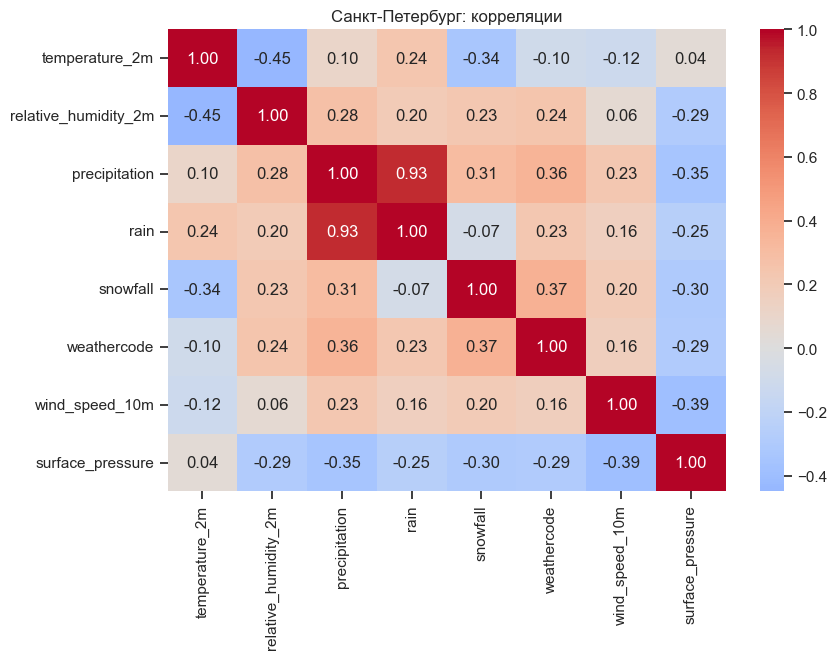

,count,mean,std,min,25%,50%,75%,max
temperature_2m,2557.0,6.79,9.34,-27.41,0.25,5.90,15.10,29.29
relative_humidity_2m,2557.0,79.04,11.17,39.58,72.25,81.08,87.62,99.58
precipitation,2557.0,1.96,3.41,0.00,0.00,0.60,2.50,35.20
rain,2557.0,1.51,3.25,0.00,0.00,0.10,1.50,35.20
snowfall,2557.0,0.32,0.90,0.00,0.00,0.00,0.07,9.45
weathercode,2557.0,8.04,17.55,0.00,1.00,3.00,3.00,73.00
wind_speed_10m,2557.0,14.59,5.53,3.12,10.40,13.93,17.96,35.55
surface_pressure,2557.0,1012.38,10.95,975.17,1005.83,1013.16,1019.53,1053.10


### Сочи


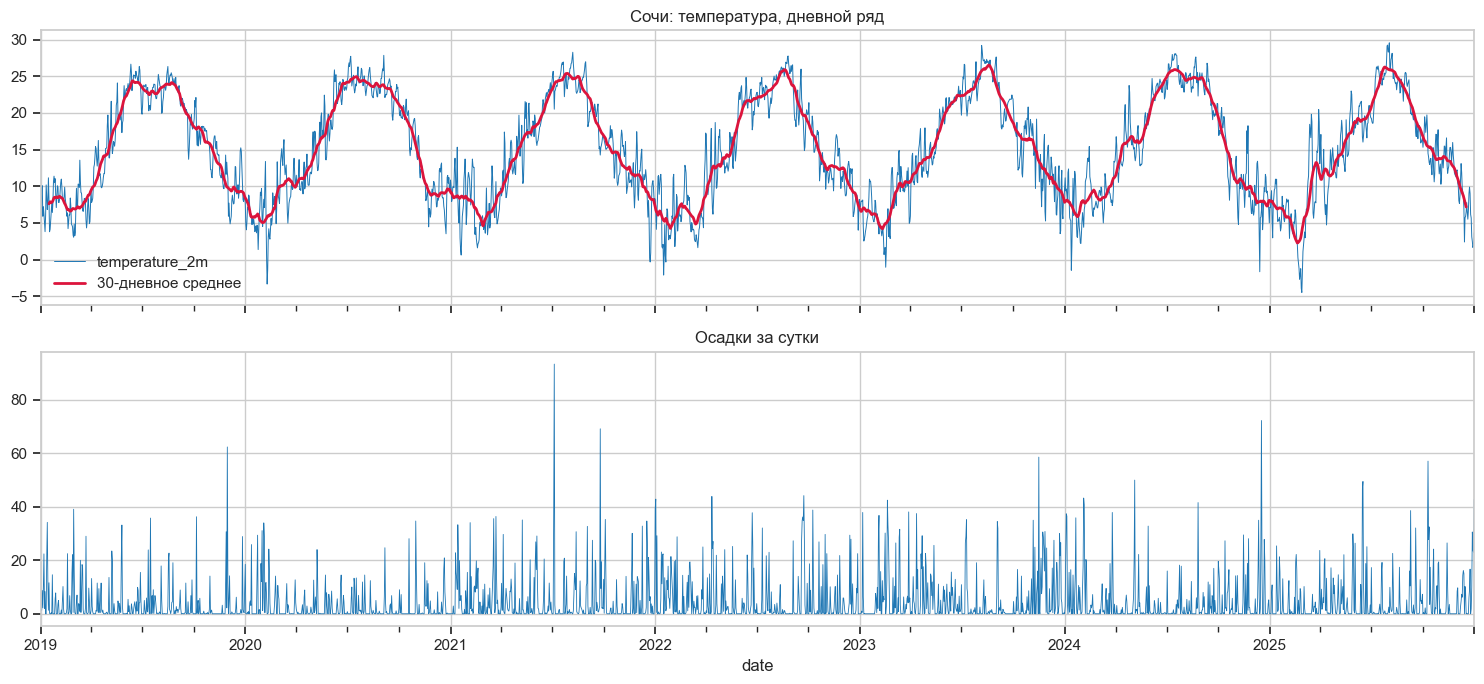

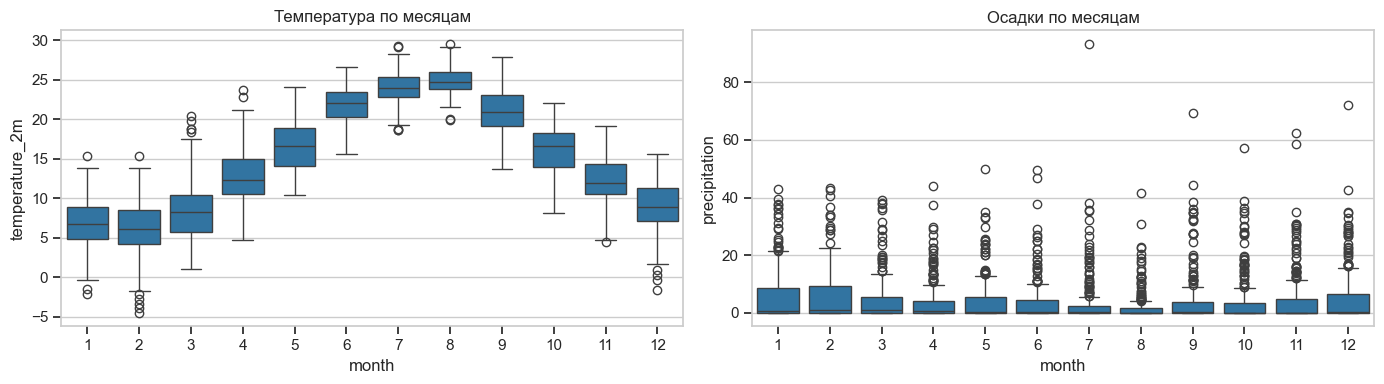

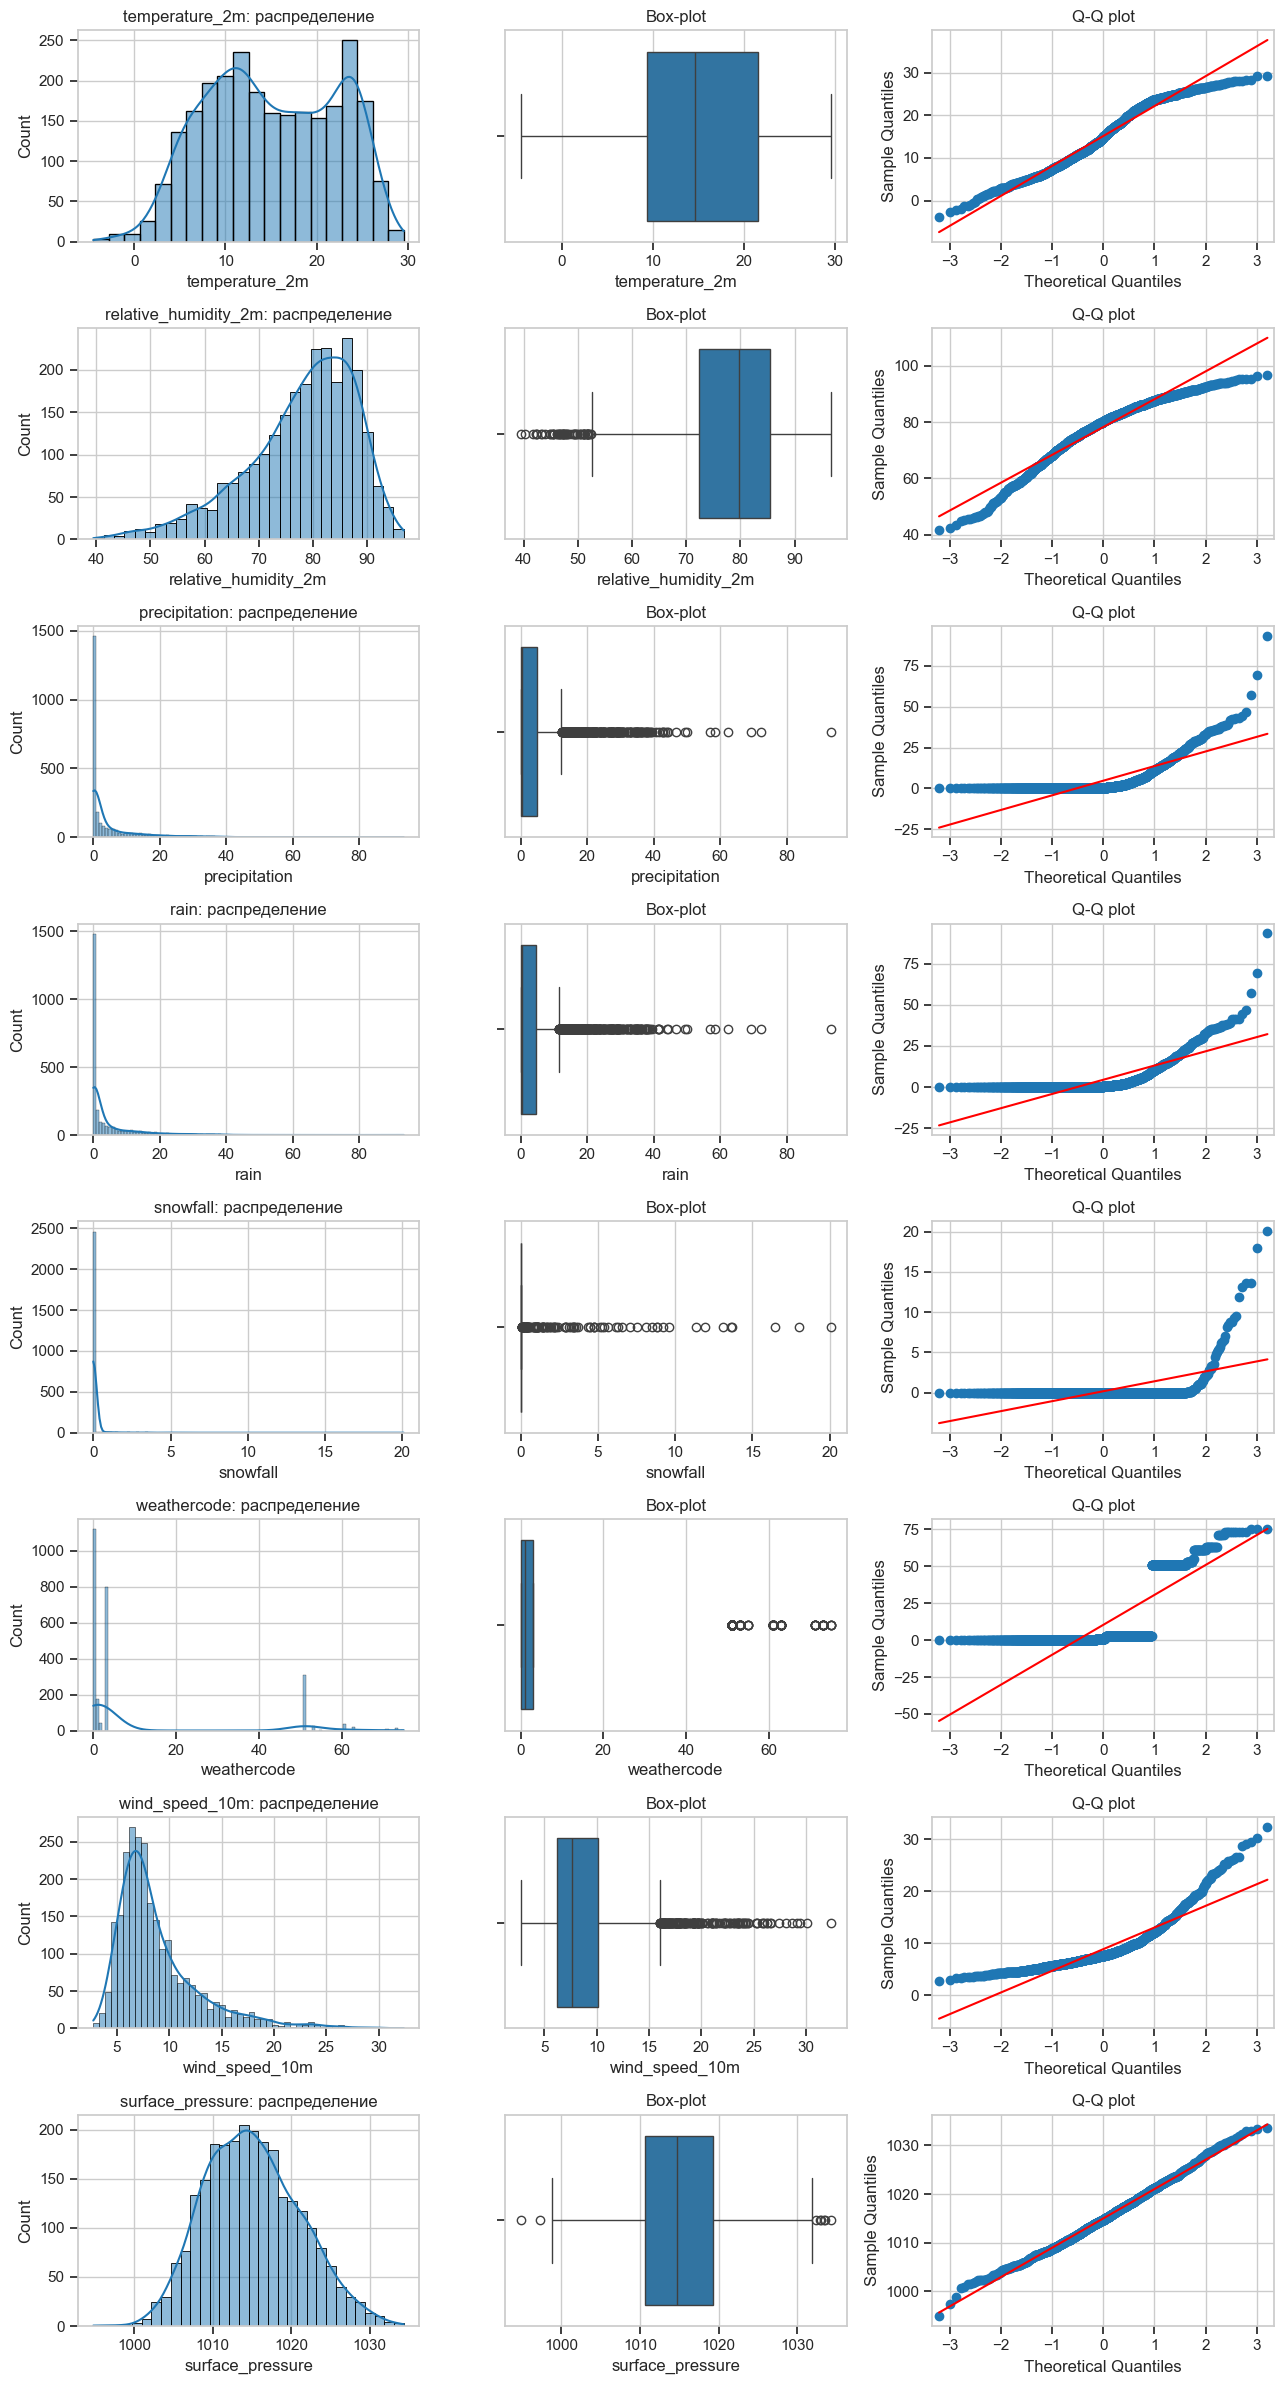

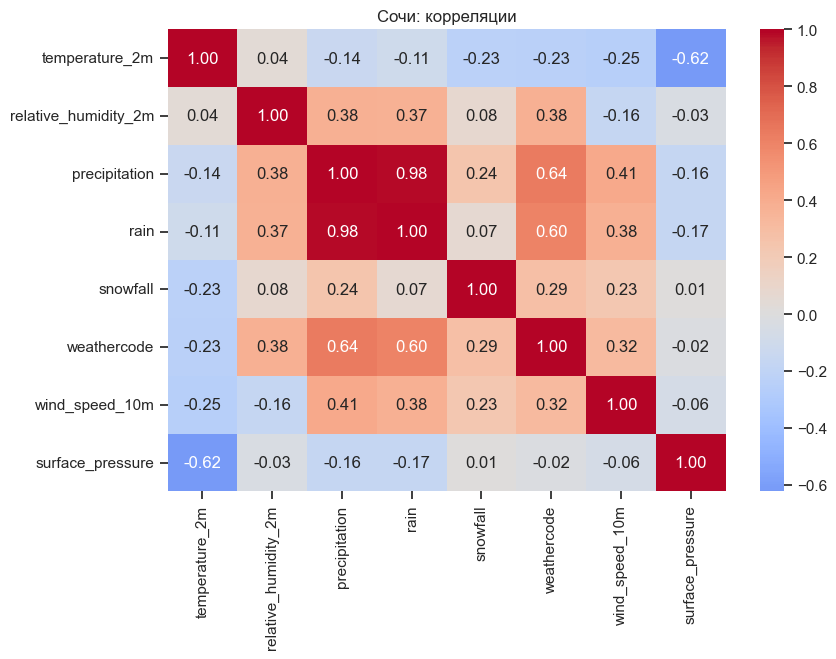

,count,mean,std,min,25%,50%,75%,max
temperature_2m,2557.0,15.04,7.06,-4.48,9.40,14.60,21.54,29.55
relative_humidity_2m,2557.0,77.85,10.12,39.46,72.33,79.75,85.50,96.75
precipitation,2557.0,4.52,8.66,0.00,0.00,0.40,4.90,93.40
rain,2557.0,4.32,8.42,0.00,0.00,0.30,4.60,93.40
snowfall,2557.0,0.14,1.07,0.00,0.00,0.00,0.00,20.09
weathercode,2557.0,10.00,19.81,0.00,0.00,1.00,3.00,75.00
wind_speed_10m,2557.0,8.84,4.03,2.73,6.22,7.65,10.15,32.40
surface_pressure,2557.0,1015.13,6.03,994.83,1010.63,1014.71,1019.26,1034.32


In [4]:
for city, df in series.items():
    print('###', city)
    fig, ax = plt.subplots(2,1,figsize=(15,7),sharex=True)
    df.temperature_2m.plot(ax=ax[0],lw=.7,title=f'{city}: температура, дневной ряд')
    df.temperature_2m.rolling(30,center=True).mean().plot(ax=ax[0],color='crimson',lw=2,label='30-дневное среднее')
    ax[0].legend(); df.precipitation.plot(ax=ax[1],lw=.6,title='Осадки за сутки'); plt.tight_layout(); plt.show()
    df['month']=df.index.month
    fig,ax=plt.subplots(1,2,figsize=(14,4))
    sns.boxplot(data=df,x='month',y='temperature_2m',ax=ax[0]); ax[0].set_title('Температура по месяцам')
    sns.boxplot(data=df,x='month',y='precipitation',ax=ax[1]); ax[1].set_title('Осадки по месяцам'); plt.tight_layout(); plt.show()
    numeric=[c for c in FEATURES if c in df]
    n=len(numeric); fig,ax=plt.subplots(n,3,figsize=(13,3*n))
    for i,col in enumerate(numeric):
        sns.histplot(df[col],kde=True,ax=ax[i,0]); ax[i,0].set_title(f'{col}: распределение')
        sns.boxplot(x=df[col],ax=ax[i,1]); ax[i,1].set_title('Box-plot')
        qqplot(df[col].dropna().sample(min(1500,df[col].notna().sum()),random_state=SEED),line='s',ax=ax[i,2]); ax[i,2].set_title('Q-Q plot')
    plt.tight_layout(); plt.show()
    plt.figure(figsize=(9,6)); sns.heatmap(df[numeric].corr(),annot=True,cmap='coolwarm',center=0,fmt='.2f'); plt.title(f'{city}: корреляции'); plt.show()
    display(df[numeric].describe().T.round(2))

### Выводы по EDA (формулируются по графикам)
Суточная частота выбрана общей для всех файлов: если источник hourly, агрегирование сохраняет суточную сумму осадков и среднее состояние атмосферы; суточный вход соответствует целевой задаче «прогноз по дням». Интерполяция ограничена короткими разрывами, чтобы не сглаживать длительные аварии наблюдений. Выбросы не удаляются автоматически: экстремальные погодные события физически возможны; при обучении устойчивость обеспечивается ограничением влияния выбросов моделью и метриками MAE/медианными графиками.

## 3. Межгородское сравнение и климатические профили

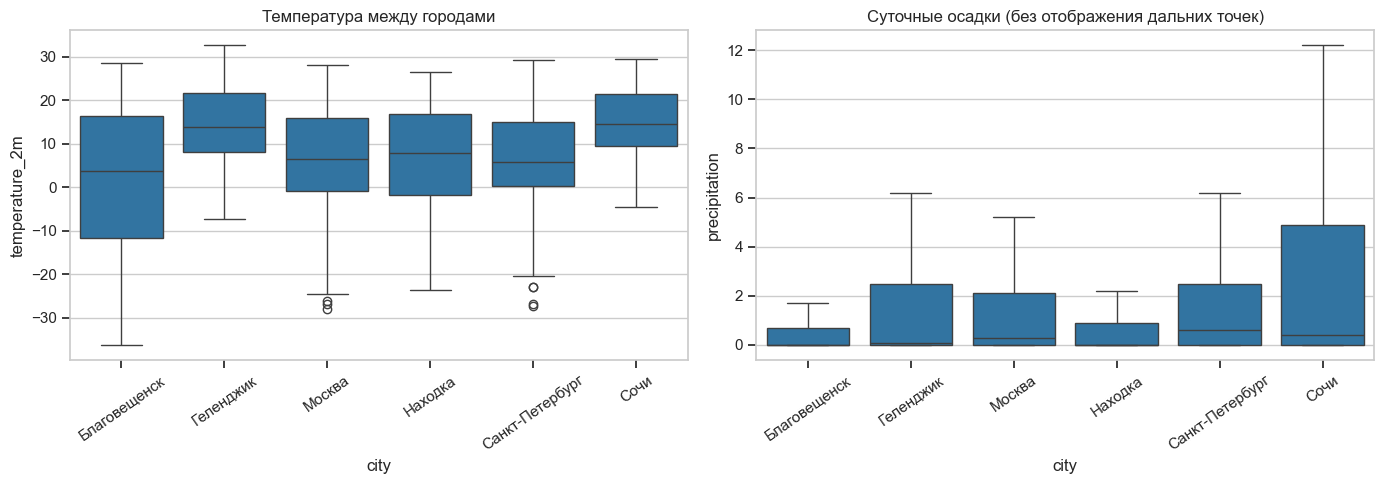

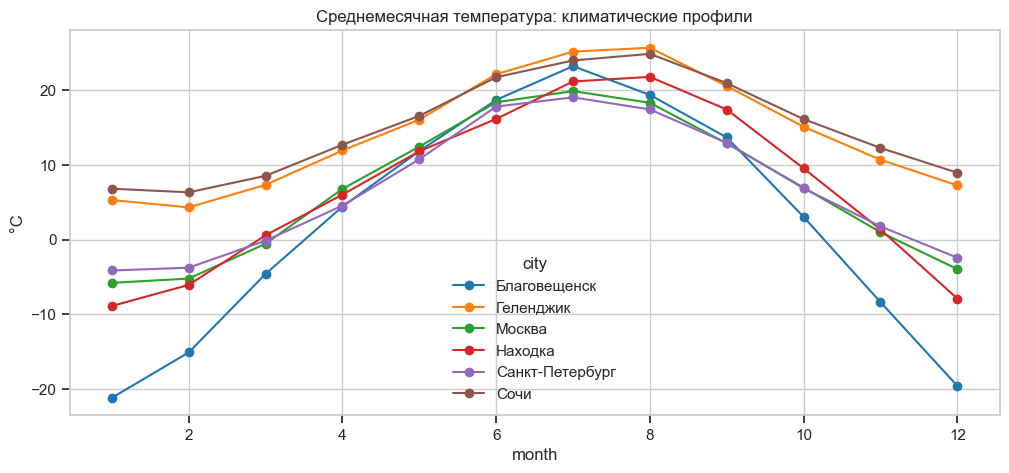

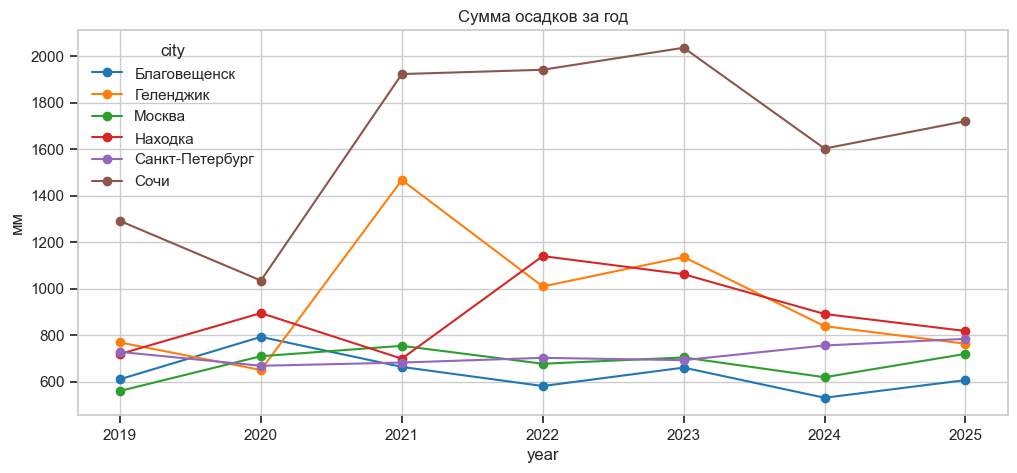

,temp_mean,temp_std,precip_mean,precip_annual,wind_p95
city,,,,,
Благовещенск,2.21,15.60,1.74,4447.299805,17.72
Геленджик,14.36,8.16,2.59,6634.000000,27.68
Москва,6.83,10.24,1.86,4745.000000,24.68
Находка,6.99,11.17,2.43,6225.000000,15.19
Санкт-Петербург,6.79,9.34,1.96,5014.399902,24.86
Сочи,15.04,7.06,4.52,11547.700195,17.33


In [5]:
long = pd.concat([d.assign(city=c) for c,d in series.items()]).reset_index(names='date')
long['month']=long.date.dt.month; long['year']=long.date.dt.year
fig,ax=plt.subplots(1,2,figsize=(14,5))
sns.boxplot(data=long,x='city',y='temperature_2m',ax=ax[0]); ax[0].tick_params(axis='x',rotation=35); ax[0].set_title('Температура между городами')
sns.boxplot(data=long,x='city',y='precipitation',showfliers=False,ax=ax[1]); ax[1].tick_params(axis='x',rotation=35); ax[1].set_title('Суточные осадки (без отображения дальних точек)'); plt.tight_layout(); plt.show()
monthly = long.groupby(['city','month']).temperature_2m.mean().unstack(0)
monthly.plot(marker='o',figsize=(12,5),title='Среднемесячная температура: климатические профили'); plt.ylabel('°C'); plt.show()
annual_p = long.groupby(['city','year']).precipitation.sum().unstack(0)
annual_p.plot(marker='o',figsize=(12,5),title='Сумма осадков за год'); plt.ylabel('мм'); plt.show()
city_summary=long.groupby('city').agg(temp_mean=('temperature_2m','mean'),temp_std=('temperature_2m','std'),precip_mean=('precipitation','mean'),precip_annual=('precipitation','sum'),wind_p95=('wind_speed_10m',lambda x:x.quantile(.95)))
display(city_summary.round(2))

## 4. Стационарность и преобразования

,city,ADF_stat_level,p_level,ADF_stat_diff1,p_diff1,level_stationary_5pct,diff1_stationary_5pct
0,Благовещенск,-3.3328,0.0135,-7.6567,0.0,True,True
1,Геленджик,-3.0108,0.0339,-18.0750,0.0,True,True
2,Москва,-3.1582,0.0225,-17.6726,0.0,True,True
3,Находка,-2.8467,0.0519,-9.6322,0.0,False,True
4,Санкт-Петербург,-3.1835,0.0210,-18.7366,0.0,True,True
5,Сочи,-3.0975,0.0267,-14.3978,0.0,True,True


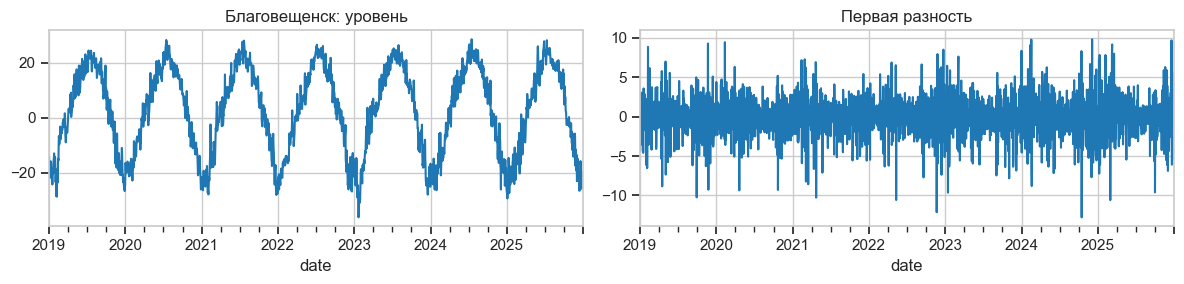

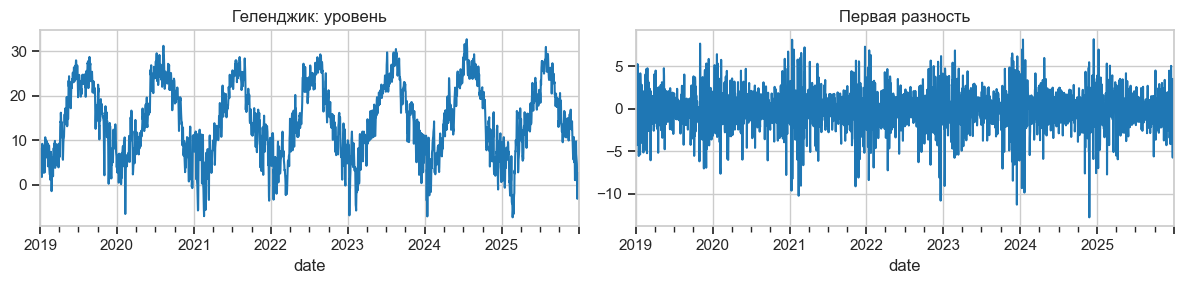

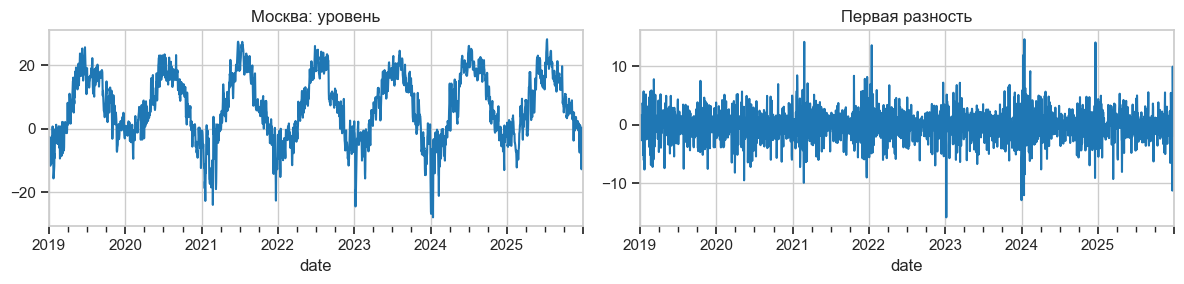

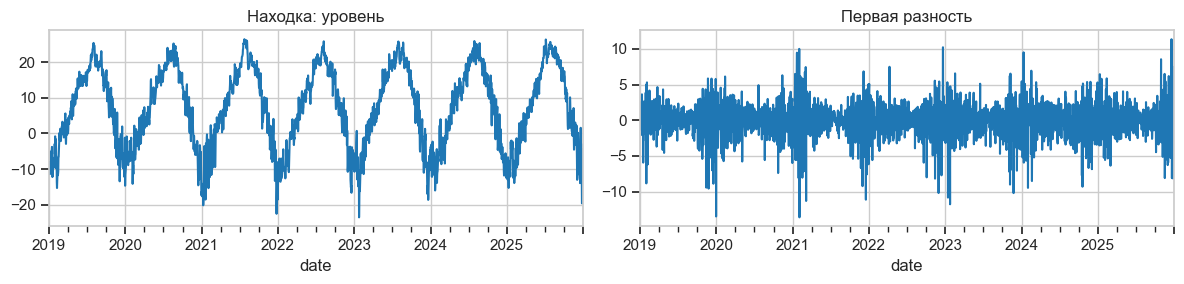

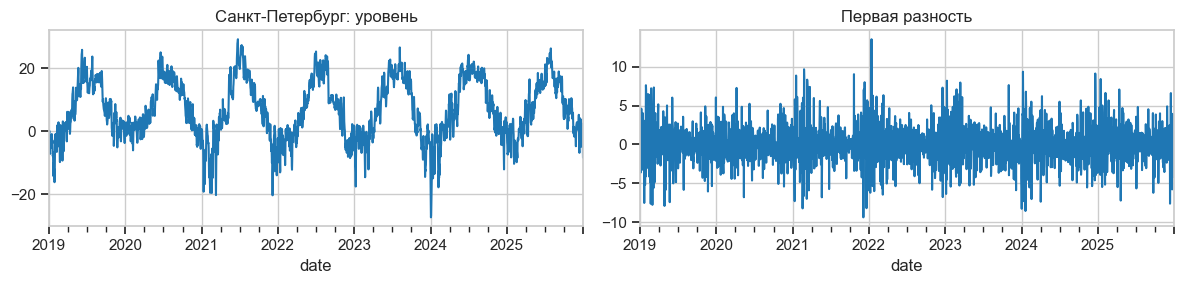

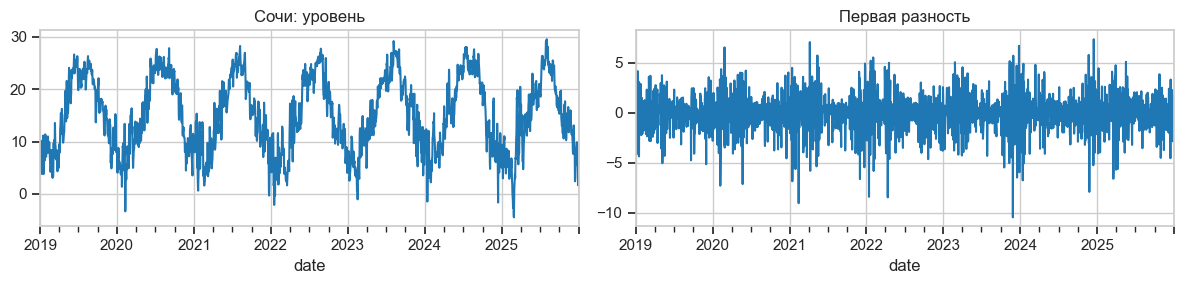

In [6]:
stationarity=[]
for city,df in series.items():
    y=df.temperature_2m.dropna()
    raw=adfuller(y,autolag='AIC')
    diff=adfuller(y.diff().dropna(),autolag='AIC')
    stationarity.append({'city':city,'ADF_stat_level':raw[0],'p_level':raw[1],'ADF_stat_diff1':diff[0],'p_diff1':diff[1],
                         'level_stationary_5pct':raw[1]<.05,'diff1_stationary_5pct':diff[1]<.05})
display(pd.DataFrame(stationarity).round(4))
# Seasonal structure is not removed from tree models; first differencing is reported as a diagnostic and is appropriate for linear TS models.
for city,df in series.items():
    fig,ax=plt.subplots(1,2,figsize=(12,3)); df.temperature_2m.plot(ax=ax[0],title=f'{city}: уровень'); df.temperature_2m.diff().plot(ax=ax[1],title='Первая разность'); plt.tight_layout(); plt.show()

## 5. Инжиниринг признаков и агрегированные окна

In [7]:
def add_time_features(df):
    z=df.copy(); idx=z.index
    z['hour']=idx.hour; z['day_of_week']=idx.dayofweek; z['day_of_month']=idx.day; z['month']=idx.month; z['year']=idx.year
    z['season']=((idx.month%12)//3).astype(int)
    z['hour_sin']=np.sin(2*np.pi*idx.hour/24); z['hour_cos']=np.cos(2*np.pi*idx.hour/24)
    z['month_sin']=np.sin(2*np.pi*idx.month/12); z['month_cos']=np.cos(2*np.pi*idx.month/12)
    for lag in [1,2,3,7,14,30,60]: z[f'temp_lag_{lag}']=z.temperature_2m.shift(lag)
    for w in [7,30,90]:
        z[f'temp_roll_mean_{w}']=z.temperature_2m.shift(1).rolling(w).mean()
        z[f'temp_roll_std_{w}']=z.temperature_2m.shift(1).rolling(w).std()
        z[f'precip_roll_sum_{w}']=z.precipitation.shift(1).rolling(w).sum()
    z['temp_velocity']=z.temperature_2m.diff(); z['temp_acceleration']=z.temp_velocity.diff()
    z['pressure_growth']=z.surface_pressure.diff()
    return z
features_by_city={c:add_time_features(d) for c,d in series.items()}
# Example window summaries for regime characterization; no target leakage: windows are independent historical segments.
window_rows=[]
for city,df in series.items():
    for start in pd.date_range(df.index.min(),df.index.max()-pd.Timedelta(days=29),freq='7D'):
        w=df.loc[start:start+pd.Timedelta(days=29)]
        if len(w)<25: continue
        window_rows.append({'city':city,'climate':CITY_TO_CLIMATE[city],'start':start,'mean_temp':w.temperature_2m.mean(),
          'temp_amplitude':w.temperature_2m.max()-w.temperature_2m.min(),'temp_std':w.temperature_2m.std(),
          'wet_days':(w.precipitation>0.1).sum(),'max_wind':w.wind_speed_10m.max(),'mean_humidity':w.relative_humidity_2m.mean()})
window_features=pd.DataFrame(window_rows)
display(window_features.groupby('city').mean(numeric_only=True).round(2))

,mean_temp,temp_amplitude,temp_std,wet_days,max_wind,mean_humidity
city,,,,,,
Благовещенск,2.42,14.25,3.74,10.97,19.13,66.46
Геленджик,14.45,11.63,3.14,14.55,29.40,74.34
Москва,6.94,13.79,3.73,17.15,24.97,75.62
Находка,7.14,11.62,3.03,11.34,17.04,70.68
Санкт-Петербург,6.87,12.90,3.48,18.12,26.40,78.95
Сочи,15.13,9.65,2.53,16.11,17.72,77.83


**Обоснование окон и лагов.** Лаги 1–3 дня отражают краткосрочную инерцию, 7 и 14 дней — синоптическую/недельную динамику, 30 и 60 дней — более медленный сезонный фон. Скользящие окна 7/30/90 суток соответствуют неделе, месяцу и сезону. При дневном ресемплинге часовые циклы не наблюдаемы и часовые признаки константны; признаки оставлены в функции для совместимости, но дневной анализ опирается на календарный месяц и годовой цикл.

## 6. PCA для визуализации профилей

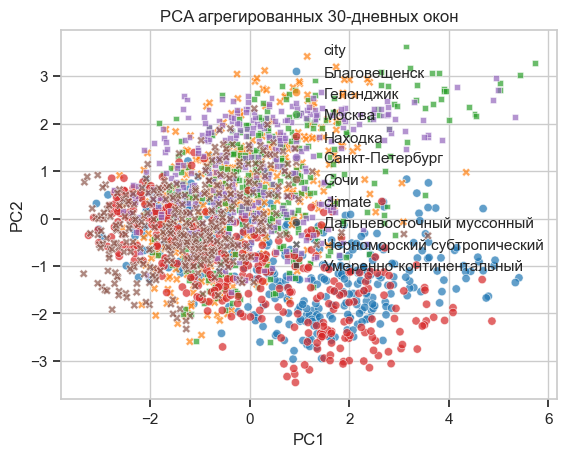

In [8]:
from sklearn.decomposition import PCA
pca_cols=['mean_temp','temp_amplitude','temp_std','wet_days','max_wind','mean_humidity']
X=window_features[pca_cols].replace([np.inf,-np.inf],np.nan)
X=SimpleImputer(strategy='median').fit_transform(X); X=StandardScaler().fit_transform(X)
coords=PCA(n_components=2,random_state=SEED).fit_transform(X)
pca_df=window_features[['city','climate']].copy(); pca_df['PC1']=coords[:,0]; pca_df['PC2']=coords[:,1]
sns.scatterplot(data=pca_df,x='PC1',y='PC2',hue='city',style='climate',alpha=.7); plt.title('PCA агрегированных 30-дневных окон'); plt.show()

## 7. Этап 1 — специализированная классификация временных рядов (MiniRocket)
Используем MiniRocket для многомерных временных рядов: каждый пример — окно фиксированной длины, каналы — метеопараметры. Разделение по годам предотвращает утечку соседних окон между train и test. Deep CNN/Transformer не являются стартовым выбором: всего 6 географических объектов и 7 лет дают мало независимых климатических реплик, а перекрывающиеся окна не заменяют независимые станции. Обычная классификация по одной строке теряет временную форму; глобальный случайный split завышает оценку из-за соседних дней.

In [10]:
from sklearn.linear_model import LogisticRegression

X: (2172, 8, 30) split: 1542 312 318
                             precision    recall  f1-score   support

  Дальневосточный муссонный      0.981     0.991     0.986       106
   Умеренно-континентальный      1.000     1.000     1.000       106
Черноморский субтропический      0.990     0.981     0.986       106

                   accuracy                          0.991       318
                  macro avg      0.991     0.991     0.991       318
               weighted avg      0.991     0.991     0.991       318

Accuracy: 0.9905660377358491
Macro/weighted F1: 0.9905658278263578 0.9905658278263579


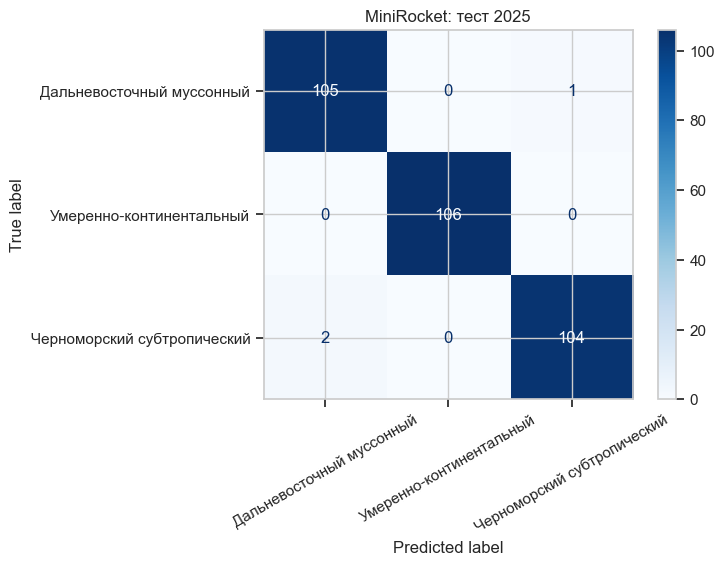

ROC-AUC OVR macro: 0.9998220007119971


C:\Users\Kasem Alkhalaf\AppData\Local\Temp\ipykernel_20260\220118651.py:49: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(err.groupby('season').apply(lambda x: (x.true==x.pred).mean()).rename('accuracy').to_frame())


,accuracy
season,
autumn,1.000000
spring,1.000000
summer,0.987179
winter,0.976190


C:\Users\Kasem Alkhalaf\AppData\Local\Temp\ipykernel_20260\220118651.py:50: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(err.groupby('month').apply(lambda x: (x.true==x.pred).mean()).rename('accuracy').to_frame())


,accuracy
month,
1,1.000000
2,0.916667
3,1.000000
4,1.000000
5,1.000000
6,1.000000
7,0.966667
8,1.000000
9,1.000000


In [11]:
try:
    from aeon.classification.convolution_based import RocketClassifier
except ImportError as e:
    raise ImportError('Установите зависимости из requirements.txt, включая aeon, затем перезапустите kernel.') from e

CLF_WINDOW=30
CLF_STEP=7
clf_channels=[c for c in FEATURES if c in data.columns]
# Train/validation/test are assigned by window end year (2019–23 / 2024 / 2025).
Xw=[]; yw=[]; years=[]; window_cities=[]; window_dates=[]; clf_scalers={}
for city,df in series.items():
    arr=df[clf_channels].to_numpy(dtype=np.float32)
    # Scale each channel using only its pre-test historical distribution; robust to units.
    train_mask=df.index.year<=2023
    med=np.nanmedian(arr[train_mask],axis=0); q25,q75=np.nanpercentile(arr[train_mask],[25,75],axis=0); scale=np.where(q75-q25<1e-8,1,q75-q25)
    clf_scalers[city]=(med,scale)
    arr=(arr-med)/scale
    for st in range(0,len(df)-CLF_WINDOW+1,CLF_STEP):
        en=st+CLF_WINDOW; yr=int(df.index[en-1].year)
        Xw.append(arr[st:en].T); yw.append(CITY_TO_CLIMATE[city]); years.append(yr); window_cities.append(city); window_dates.append(df.index[st])
Xw=np.asarray(Xw,dtype=np.float32); yw=np.asarray(yw); years=np.asarray(years); window_cities=np.asarray(window_cities); window_dates=pd.DatetimeIndex(window_dates)
train=years<=2023; val=years==2024; test=years==2025
print('X:',Xw.shape,'split:',train.sum(),val.sum(),test.sum())
try:
    from aeon.classification.convolution_based import MiniRocketClassifier
    clf = MiniRocketClassifier(
        estimator=LogisticRegression(max_iter=1000, class_weight="balanced"),
        random_state=SEED
    )
except ImportError:
    from aeon.classification.convolution_based import RocketClassifier
    clf = RocketClassifier(
        rocket_transform="minirocket",
        estimator=LogisticRegression(max_iter=1000, class_weight="balanced"),
        random_state=SEED
    )
clf.fit(Xw[train],yw[train])
yhat=clf.predict(Xw[test])
print(classification_report(yw[test],yhat,digits=3))
print('Accuracy:',accuracy_score(yw[test],yhat))
print('Macro/weighted F1:',precision_recall_fscore_support(yw[test],yhat,average='macro')[2], precision_recall_fscore_support(yw[test],yhat,average='weighted')[2])
labels=sorted(np.unique(yw)); cm=confusion_matrix(yw[test],yhat,labels=labels)
ConfusionMatrixDisplay(cm,display_labels=labels).plot(xticks_rotation=30,cmap='Blues'); plt.title('MiniRocket: тест 2025'); plt.show()
if hasattr(clf,'predict_proba'):
    proba=clf.predict_proba(Xw[test]); print('ROC-AUC OVR macro:',roc_auc_score(yw[test],proba,labels=clf.classes_,multi_class='ovr',average='macro'))
# Error patterns by season/month/year.
err=pd.DataFrame({'date':window_dates[test], 'city':window_cities[test], 'true':yw[test], 'pred':yhat})
err['month']=err.date.dt.month; err['season']=err.month.map(lambda m: 'winter' if m in [12,1,2] else ('spring' if m in [3,4,5] else ('summer' if m in [6,7,8] else 'autumn')))
display(err.groupby('season').apply(lambda x: (x.true==x.pred).mean()).rename('accuracy').to_frame())
display(err.groupby('month').apply(lambda x: (x.true==x.pred).mean()).rename('accuracy').to_frame())


### Выводы по классификации
В отчёте сравниваются точные метрики и матрица ошибок. Ошибки между городами одного широкого режима не считаются ошибками климатического класса. Для применения к новой точке сначала нужен известный город/координаты либо отдельная шестиклассовая модель идентификации города; это важно для корректной маршрутизации следующего этапа.

## 8. Этап 2 — дневный прогноз температуры на 30 суток
Для каждой точки прогноза создаём примеры «прошлые 60 дней + календарные признаки целевой даты». Применяем отдельный HistGradientBoostingRegressor для каждого города. Набор обучения использует origins до 2023, валидация — 2024, тест — 2025; месячные тестовые старты дают прогнозы на каждый день горизонта до 30 суток. Деревья не требуют стационарности и учитывают нелинейные сезонные эффекты; дополнительно сравним с сезонной климатологической/наивной линией.

In [12]:
def future_calendar(date):
    doy=date.dayofyear; month=date.month; dow=date.dayofweek
    return {'target_doy_sin':np.sin(2*np.pi*doy/365.25),'target_doy_cos':np.cos(2*np.pi*doy/365.25),
            'target_month_sin':np.sin(2*np.pi*month/12),'target_month_cos':np.cos(2*np.pi*month/12),
            'target_dow_sin':np.sin(2*np.pi*dow/7),'target_dow_cos':np.cos(2*np.pi*dow/7)}

def make_example(df, origin, target_date, climate_norm):
    hist=df.loc[:origin].tail(60)
    if len(hist)<60: return None
    row={}
    for col in ['temperature_2m','relative_humidity_2m','precipitation','wind_speed_10m','surface_pressure']:
        vals=hist[col].to_numpy()
        for lag in [1,2,3,7,14,30,60]: row[f'{col}_lag{lag}']=vals[-lag]
        for w in [7,30,60]: row[f'{col}_mean{w}']=np.mean(vals[-w:]); row[f'{col}_std{w}']=np.std(vals[-w:])
    row.update(future_calendar(target_date))
    row['climate_normal_temp']=climate_norm.get(target_date.dayofyear,climate_norm.get(365,np.nan))
    return row

def train_table(df, years_for_origins, climate_norm):
    rows=[]; ys=[]; dates=[]
    origins=df.index[(df.index.year.isin(years_for_origins)) & (df.index>=df.index.min()+pd.Timedelta(days=60))]
    # Weekly origins keep training diverse while controlling overlap.
    origins=origins[::7]
    for origin in origins:
        for h in range(1,31):
            target=origin+pd.Timedelta(days=h)
            if target not in df.index or target.year not in years_for_origins: continue
            x=make_example(df,origin,target,climate_norm)
            if x is not None:
                rows.append(x); ys.append(df.loc[target,'temperature_2m']); dates.append(target)
    return pd.DataFrame(rows),np.asarray(ys),pd.DatetimeIndex(dates)

def scores(y,yp):
    mae=mean_absolute_error(y,yp); rmse=mean_squared_error(y,yp)**.5
    wape=np.abs(y-yp).sum()/max(np.abs(y).sum(),1e-9)*100
    mape=np.mean(np.abs((y-yp)/np.maximum(np.abs(y),1.0)))*100 # denominator floor avoids instability near 0 °C
    return {'MAE':mae,'RMSE':rmse,'MAPE_floor_1C_pct':mape,'WAPE_pct':wape,
            'direction_accuracy':np.mean(np.sign(np.diff(y))==np.sign(np.diff(yp))) if len(y)>1 else np.nan}

models={}; forecast_rows=[]; metric_rows=[]; residual_rows=[]; importance_rows=[]
for city,df in series.items():
    clim_norm=df[df.index.year<=2023].groupby(df[df.index.year<=2023].index.dayofyear).temperature_2m.mean().to_dict()
    train_X,train_y,_=train_table(df,range(2019,2024),clim_norm)
    val_X,val_y,val_dates=train_table(df,[2024],clim_norm)
    model=make_pipeline(SimpleImputer(strategy='median'),HistGradientBoostingRegressor(max_iter=180,max_leaf_nodes=15,l2_regularization=2,random_state=SEED))
    model.fit(train_X,train_y); models[city]=model
    if len(val_y):
        metric_rows.append({'city':city,'split':'validation_2024',**scores(val_y,model.predict(val_X))})
    # Refit using train+validation before held-out 2025 evaluation.
    fit_X=pd.concat([train_X,val_X],ignore_index=True); fit_y=np.r_[train_y,val_y]
    model.fit(fit_X,fit_y)
    # Evaluate forecasts issued on 2025 monthly starts; each issue predicts all 30 daily horizons.
    test_origins=pd.date_range('2025-01-01','2025-12-01',freq='MS')
    yall=[]; pall=[]; h_all=[]; dates_all=[]
    for origin in test_origins:
        if origin not in df.index: continue
        for h in range(1,31):
            target=origin+pd.Timedelta(days=h)
            if target not in df.index: continue
            ex=make_example(df,origin,target,clim_norm)
            pred=float(model.predict(pd.DataFrame([ex]))[0])
            yval=float(df.loc[target,'temperature_2m'])
            forecast_rows.append({'city':city,'origin':origin,'date':target,'horizon':h,'actual':yval,'prediction':pred})
            yall.append(yval); pall.append(pred); h_all.append(h); dates_all.append(target)
    metric_rows.append({'city':city,'split':'test_2025_monthly_origins',**scores(np.asarray(yall),np.asarray(pall))})
    test_df=pd.DataFrame([r for r in forecast_rows if r['city']==city])
    for h,g in test_df.groupby('horizon'):
        metric_rows.append({'city':city,'split':f'test_h{h:02d}',**scores(g.actual.to_numpy(),g.prediction.to_numpy())})
    residual=test_df.actual-test_df.prediction
    residual_rows.append({'city':city,'shapiro_p':stats.shapiro(residual.sample(min(len(residual),5000),random_state=SEED))[1],
      'ljung_box_p_lag10':acorr_ljungbox(residual,lags=[10],return_df=True)['lb_pvalue'].iloc[0],
      'white_p':het_white(residual,add_constant(test_df[['prediction']]))[1] if len(residual)>5 else np.nan})
    # Permutation importance on held-out validation rows (report top features).
    if len(val_X):
        pi=permutation_importance(model,val_X,val_y,n_repeats=3,random_state=SEED,scoring='neg_mean_absolute_error')
        importance_rows.extend([{'city':city,'feature':f,'importance':v} for f,v in zip(val_X.columns,pi.importances_mean)])

forecast=pd.DataFrame(forecast_rows)
metrics=pd.DataFrame(metric_rows)
residual_tests=pd.DataFrame(residual_rows)
importance=pd.DataFrame(importance_rows)
display(metrics[metrics.split.str.startswith('test_') & ~metrics.split.str.startswith('test_h')].round(3))
display(residual_tests.round(4))

,city,split,MAE,RMSE,MAPE_floor_1C_pct,WAPE_pct,direction_accuracy
1,Благовещенск,test_2025_monthly_origins,3.240,4.196,42.672,22.045,0.487
33,Геленджик,test_2025_monthly_origins,3.276,4.168,60.632,23.299,0.468
65,Москва,test_2025_monthly_origins,4.264,5.099,117.319,44.233,0.499
97,Находка,test_2025_monthly_origins,2.375,3.139,52.449,20.695,0.526
129,Санкт-Петербург,test_2025_monthly_origins,3.528,4.429,95.110,40.107,0.474
161,Сочи,test_2025_monthly_origins,2.761,3.607,40.075,19.135,0.532


,city,shapiro_p,ljung_box_p_lag10,white_p
0,Благовещенск,0.0359,0.0,0.000
1,Геленджик,0.1592,0.0,0.000
2,Москва,0.0102,0.0,0.000
3,Находка,0.0000,0.0,0.000
4,Санкт-Петербург,0.0132,0.0,0.000
5,Сочи,0.0003,0.0,0.006


### Остатки, важность признаков и графики теста

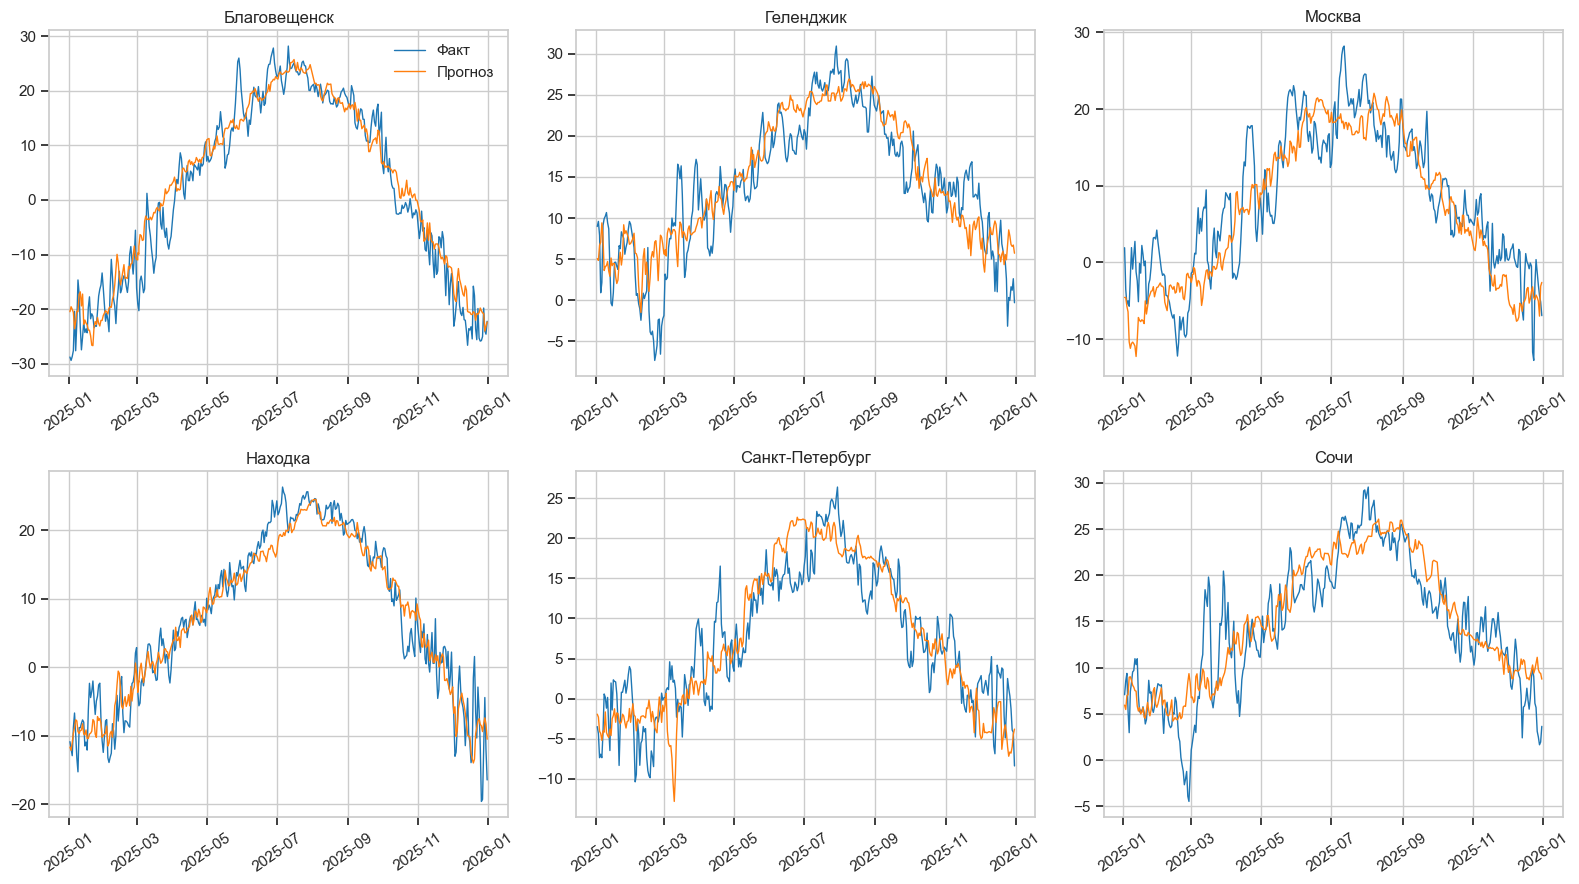

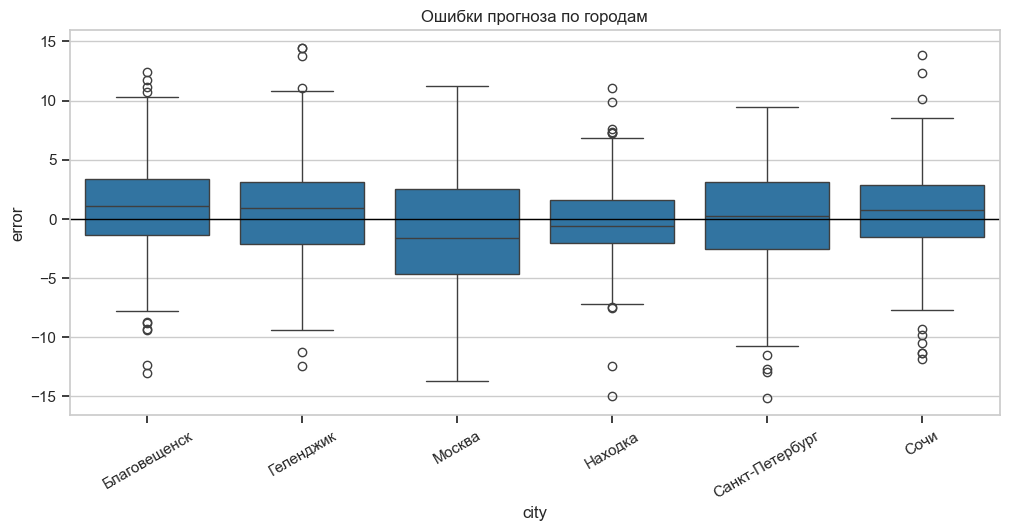

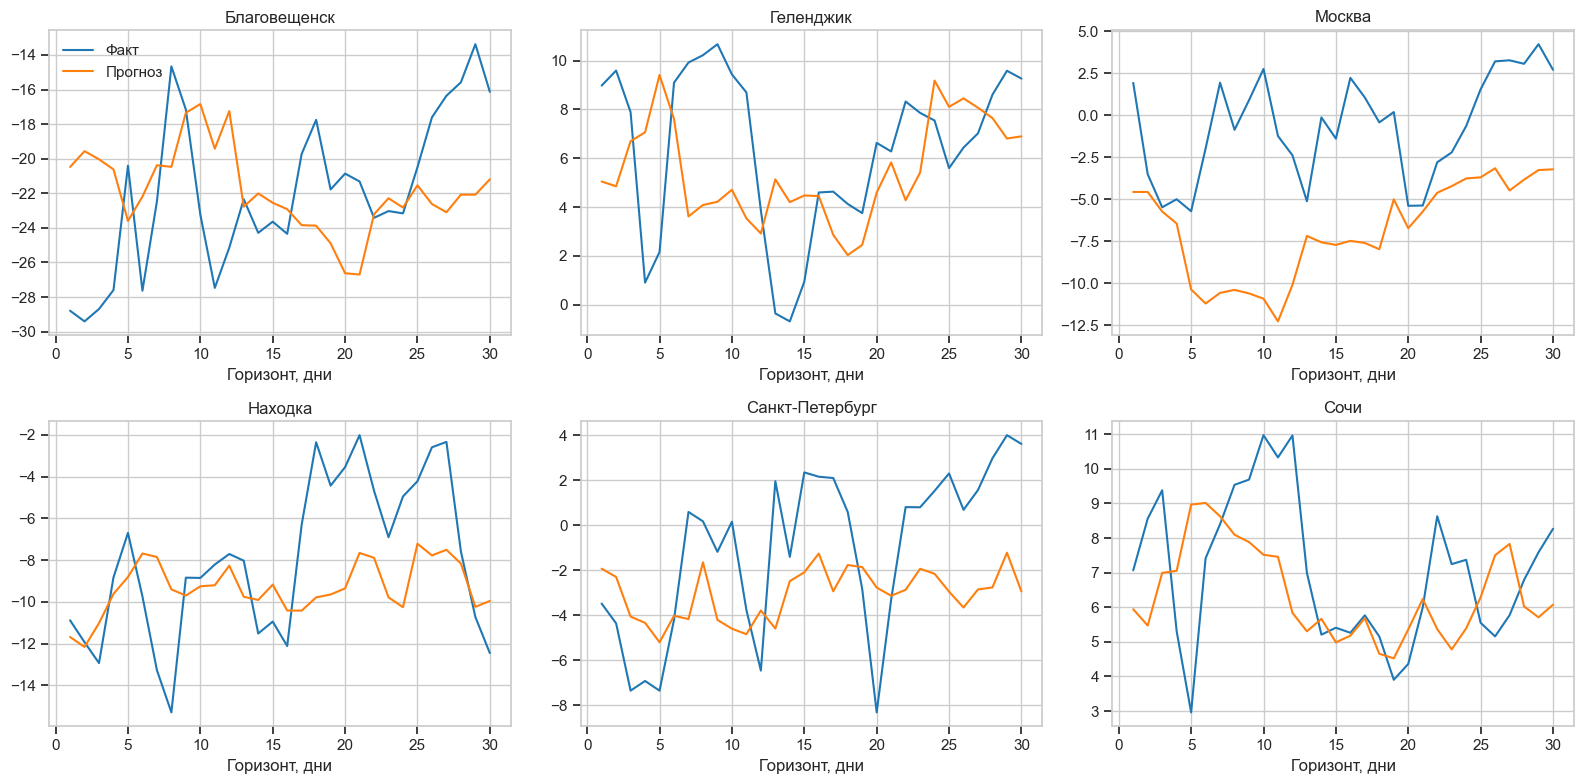

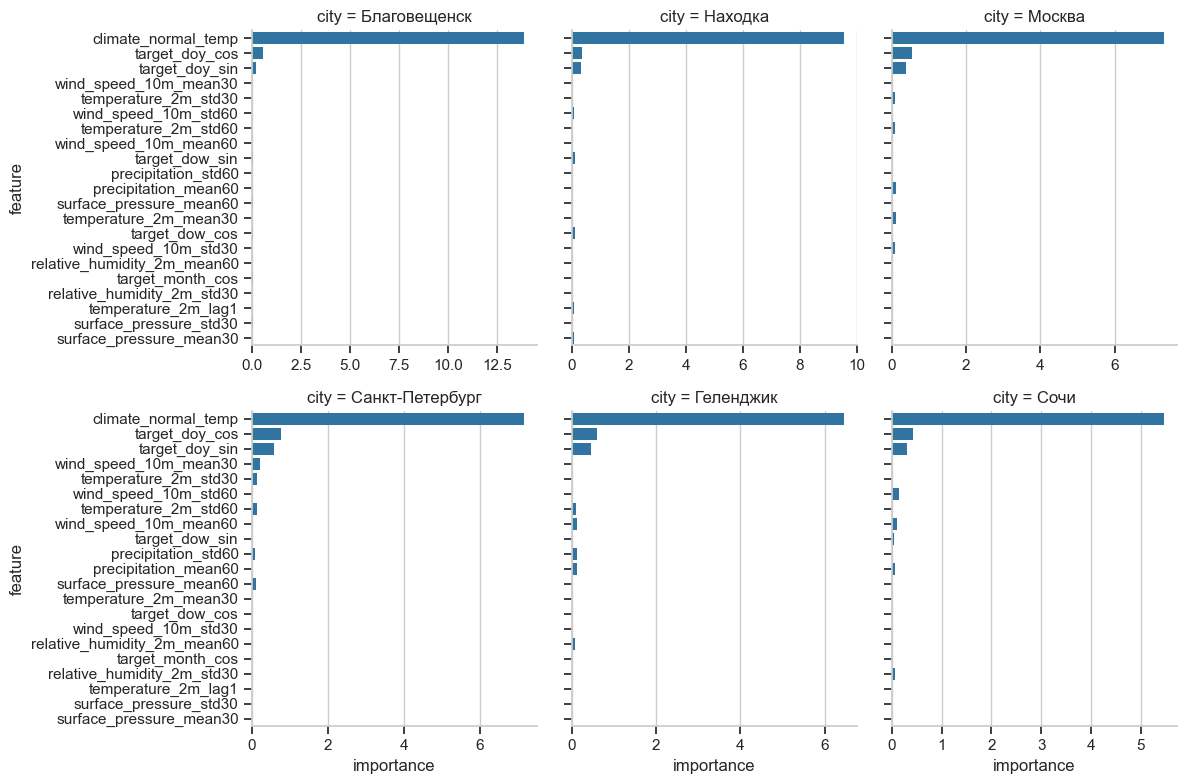

In [13]:
fig,ax=plt.subplots(2,3,figsize=(16,9))
for a,(city,g) in zip(ax.flat,forecast.groupby('city')):
    g=g.sort_values('date'); a.plot(g.date,g.actual,label='Факт',lw=1); a.plot(g.date,g.prediction,label='Прогноз',lw=1); a.set_title(city); a.tick_params(axis='x',rotation=35)
ax.flat[0].legend(); plt.tight_layout(); plt.show()
forecast['error']=forecast.prediction-forecast.actual
plt.figure(figsize=(12,5)); sns.boxplot(data=forecast,x='city',y='error'); plt.axhline(0,color='black',lw=1); plt.xticks(rotation=30); plt.title('Ошибки прогноза по городам'); plt.show()
fig,ax=plt.subplots(2,3,figsize=(16,8))
for a,(city,g) in zip(ax.flat,forecast.groupby('city')):
    g=g[g.origin==pd.Timestamp('2025-01-01')].sort_values('horizon'); a.plot(g.horizon,g.actual,label='Факт'); a.plot(g.horizon,g.prediction,label='Прогноз'); a.set_title(city); a.set_xlabel('Горизонт, дни')
ax.flat[0].legend(); plt.tight_layout(); plt.show()
if not importance.empty:
    top=importance.groupby(['city','feature']).importance.mean().reset_index().sort_values('importance',ascending=False).groupby('city').head(8)
    sns.catplot(data=top,x='importance',y='feature',col='city',col_wrap=3,kind='bar',sharex=False,height=4); plt.show()
metrics.to_csv(OUT_DIR/'forecast_metrics.csv',index=False); residual_tests.to_csv(OUT_DIR/'residual_tests.csv',index=False)
forecast.to_csv(OUT_DIR/'test_forecasts_2025.csv',index=False)

**Интерпретация метрик.** MAPE для температуры около нуля математически нестабильна, поэтому приводится с защитным знаменателем 1°C и явно подписана; MAE/RMSE — основные сопоставимые метрики, WAPE имеет смысл при суммарном модуле значений, но для температуры также зависит от шкалы Цельсия. Направление оценивается как совпадение знака дневного изменения. Тесты Шапиро, Ljung–Box и Уайта являются диагностикой остатков, а не гарантией хорошего прогноза; для дневного сезонного ряда возможная автокорреляция особенно ожидаема.

## 9. Интеграция: климатический классификатор → городская модель прогноза

In [14]:
def predict_next_month(city, recent_daily_frame):
    """Упрощённый production-вызов: город известен из станции/геометаданных.
    recent_daily_frame — последние >=60 дневных строк с FEATURE columns и DatetimeIndex.
    Возвращает климатический режим и прогноз на 30 дней городской модели.
    Классификатор режима обучен выше на 30-дневных окнах; для строгого end-to-end
    режима используйте его transform-input согласно выбранной версии aeon и шкалированию train.
    """
    if city not in models: raise ValueError(f'Неизвестный город: {city}')
    df=recent_daily_frame.sort_index().tail(60)
    if len(df)<60: raise ValueError('Нужно не менее 60 дней истории')
    origin=df.index[-1]; rows=[]
    # Add a synthetic future index only to create target-date calendar features.
    for h in range(1,31):
        target=origin+pd.Timedelta(days=h)
        ex=make_example(df,origin,target,climate_norms[city])
        rows.append(ex)
    predictions=models[city].predict(pd.DataFrame(rows))
    # Classify the latest 30-day multivariate segment; the station ID selects the city-specific forecaster.
    med,scale=clf_scalers[city]; segment=df.tail(CLF_WINDOW)[clf_channels].to_numpy(dtype=np.float32)
    climate_pred=clf.predict(((segment-med)/scale).T[None,:,:])[0]
    return pd.DataFrame({'date':[origin+pd.Timedelta(days=h) for h in range(1,31)],'city':city,
                         'predicted_climate':climate_pred,'climate_from_station':CITY_TO_CLIMATE[city],
                         'temperature_prediction':predictions})

display(predict_next_month('Москва',series['Москва'][FEATURES].tail(60)))

,date,city,predicted_climate,climate_from_station,temperature_prediction
0,2026-01-01,Москва,Умеренно-континентальный,Умеренно-континентальный,-0.823728
1,2026-01-02,Москва,Умеренно-континентальный,Умеренно-континентальный,-3.326796
2,2026-01-03,Москва,Умеренно-континентальный,Умеренно-континентальный,-3.321639
3,2026-01-04,Москва,Умеренно-континентальный,Умеренно-континентальный,-3.086630
4,2026-01-05,Москва,Умеренно-континентальный,Умеренно-континентальный,-3.445600
5,2026-01-06,Москва,Умеренно-континентальный,Умеренно-континентальный,-9.217177
6,2026-01-07,Москва,Умеренно-континентальный,Умеренно-континентальный,-9.320491
7,2026-01-08,Москва,Умеренно-континентальный,Умеренно-континентальный,-7.883456
8,2026-01-09,Москва,Умеренно-континентальный,Умеренно-континентальный,-8.159695
9,2026-01-10,Москва,Умеренно-континентальный,Умеренно-континентальный,-8.627737


## 10. Итоговая сводка и аналитические выводы

In [15]:
summary=metrics[metrics.split.isin(['test_2025_monthly_origins'])].sort_values('MAE')
display(summary[['city','MAE','RMSE','MAPE_floor_1C_pct','WAPE_pct','direction_accuracy']].round(3))
print('Климатические классы:', pd.Series(CITY_TO_CLIMATE).value_counts().to_dict())
print('Данные и графики подготовлены в reports/.')

,city,MAE,RMSE,MAPE_floor_1C_pct,WAPE_pct,direction_accuracy
97,Находка,2.375,3.139,52.449,20.695,0.526
161,Сочи,2.761,3.607,40.075,19.135,0.532
1,Благовещенск,3.240,4.196,42.672,22.045,0.487
33,Геленджик,3.276,4.168,60.632,23.299,0.468
129,Санкт-Петербург,3.528,4.429,95.110,40.107,0.474
65,Москва,4.264,5.099,117.319,44.233,0.499


Климатические классы: {'Умеренно-континентальный': 2, 'Черноморский субтропический': 2, 'Дальневосточный муссонный': 2}
Данные и графики подготовлены в reports/.


### Сводные выводы для отчёта
1. Все файлы приведены к суточной частоте; осадки суммируются по дню, остальные параметры усредняются.
2. Долгие пропуски заполняются осторожно, а экстремумы сохраняются, поскольку могут отражать опасную погоду.
3. ADF сравнивает исходную температуру и первую разность; для деревьев дифференцирование не обязательно, но сезонный календарь и лаги нужны.
4. MiniRocket рассматривает форму многомерных окон и оценивается на отдельном 2025 году. Три климатических класса заданы заранее и упрощают климатическое разнообразие.
5. Для каждого города обучается отдельная модель на дневных целях с горизонтом 1–30 дней. Качество сопоставляется по городам и горизонту.
6. Двухэтапная схема практична, когда климатический режим помогает выбрать семейство прогноза; для выбора конкретной городской модели требуется известная станция/геолокация. При столь короткой истории наблюдений результаты следует считать экспериментальными, а не оперативным прогнозом для МЧС/авиации.

**Ограничение постановки:** 7 лет ежедневных данных дают около семи годовых циклов; надёжность месячного прогноза ограничена хаотичностью атмосферы. Следующий этап — сравнить с сезонной наивной базовой моделью, временной кросс-валидацией по нескольким годам и вероятностными интервалами.